# **AI METHODS I**
## Day IV · Notebook 3: Object detection with YOLO and segmentation with SAM

| Notebook | Topic |
|---|---|
| 1 | Neural network fundamentals and tensors |
| 2 | Computer vision with hand-written rules: OpenCV |
| **3 · this one** | Computer vision that **learns**: YOLO and SAM |

In notebook 2 we wrote rules by hand and watched them break: merged vests, missed orange vests, facades where windows and stone frames look alike. Today we let a **neural network learn the rules** from thousands of labelled photos, and build a **construction-site safety detector**: people, helmets, vests, masks, cones and machinery, *and* the people **without** helmets or vests.

Three tasks, three levels of detail:

```
 CLASSIFICATION          DETECTION                       SEGMENTATION
 "what is in the image?" "what, and where?" (boxes)      "which pixels exactly?" (masks)

  ┌─────────────┐         ┌─────────────┐                 ┌─────────────┐
  │   o    o    │         │ ┌─┐    ┌─┐  │                 │  ▓    ▓     │
  │  /|\  /|\   │         │ │o│    │o│  │                 │ ▓▓▓  ▓▓▓    │
  │  / \  / \   │         │ └─┘    └─┘  │                 │ ▓ ▓  ▓ ▓    │
  └─────────────┘         └─────────────┘                 └─────────────┘
  → "construction site"   → 2 x person, 1 x no-helmet     → exact outline of each worker
                            (+ confidence)
  e.g. ResNet             e.g. YOLO                       e.g. SAM, YOLO-seg
```

### Learning goals
By the end of this notebook you will be able to:
1. Explain how a **convolutional neural network** builds features from pixels, and what **transfer learning** is.
2. Read a detector's output (**boxes, classes, confidences**) and explain **IoU** and **non-maximum suppression**.
3. Prepare a dataset in **YOLO format**, and know how to **annotate your own**.
4. **Fine-tune** a YOLO model, and choose where to train it: your **laptop**, a **free cloud GPU** or a **rented GPU**.
5. Evaluate a detector with **precision, recall and mAP**, choose a **confidence threshold**, and run it on images and video.
6. Use **SAM** to segment objects from a point or a box, chain **YOLO → SAM**, and **auto-annotate** data.

### Table of contents
0. Setup
1. CNNs: from hand-made filters to learned features
2. What a detector outputs: boxes, IoU and NMS
3. A pretrained YOLO: what it can and cannot see
4. The dataset: construction site safety
5. Building your own dataset
6. Where to train: three tiers
7. Fine-tuning YOLO
8. Evaluation: precision, recall and mAP
9. Inference: a site safety report, and the video
10. Segment Anything (SAM)
11. Saving and sharing the model
12. Summary
13. Your turn
14. Conclusions and next steps

> **How to use this notebook:** run the cells from top to bottom.
> - **With an NVIDIA GPU** (your laptop, Google Colab or Kaggle), the notebook **trains** the detector: about 40 minutes with the default settings.
> - **Without a GPU**, it **downloads the detector we trained for the course** from Hugging Face and skips training, so the whole notebook runs on a normal laptop in a few minutes. You can still train on your CPU if you want (section 6).
> - Once a model is trained, the notebook reuses it unless you set `RETRAIN = True`.

# 0. Setup

We use **Ultralytics**, the library behind YOLO. It trains, evaluates and runs YOLO and SAM models with a few lines of code (on top of PyTorch, notebook 1).

💡 **Tip – Google Colab or Kaggle:** run the next cell first, and switch on a GPU (Colab: *Runtime → Change runtime type → T4 GPU*; Kaggle: *Settings → Accelerator → GPU*). See section 6.

In [1]:
# Only needed in Google Colab, Kaggle or a new environment: remove the "#" and run this cell once.
# %pip install ultralytics huggingface_hub "kagglehub[pandas-datasets]" opencv-python lap

In [2]:
import shutil
import time
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import requests
import torch
import yaml
import kagglehub as kh
from huggingface_hub import hf_hub_download
from ultralytics import YOLO, SAM

In [3]:
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")            # downloaded and trained weights (.pt files): large, keep out of git
RUNS_DIR = Path("runs").resolve()     # Ultralytics training outputs (an absolute path keeps them in this folder)
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR]:
    folder.mkdir(exist_ok=True)

# Ultralytics keeps per-user settings; point its default folders here so nothing lands elsewhere on your disk
from ultralytics import settings
settings.update({"weights_dir": str(MODEL_DIR.resolve()), "runs_dir": str(RUNS_DIR)})

sns.set_theme(style="whitegrid", context="notebook")
%config InlineBackend.figure_formats = ["jpeg"]   # photos as JPEG: a much smaller notebook file
plt.rcParams["figure.figsize"] = (10, 6)
RANDOM_STATE = 42

DEVICE = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print(f"PyTorch {torch.__version__}, device: {DEVICE}" + (f" ({torch.cuda.get_device_name(0)})" if DEVICE == "cuda" else ""))


def save_fig(name):
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")


def show_image(image, title=None, ax=None):
    # Show an OpenCV (BGR) image with matplotlib (RGB)
    ax = ax or plt.gca()
    ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB) if image.ndim == 3 else image, cmap=None if image.ndim == 3 else "gray")
    ax.set_axis_off()
    if title:
        ax.set_title(title)

PyTorch 2.14.1+cu126, device: cuda (NVIDIA GeForce RTX 4050 Laptop GPU)


## 0.1 The dataset and the test media

| Data | What | Licence |
|---|---|---|
| **Construction Site Safety** | 2,801 site photos with boxes for 10 classes, YOLO format; [Kaggle](https://www.kaggle.com/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow), originally from [Roboflow Universe](https://universe.roboflow.com/roboflow-universe-projects/construction-site-safety) | CC BY 4.0 |
| `site_visit.jpg` | Site visit, naval hospital construction site, by NAVFAC ([Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Navy_Surgeon_General_Takes_a_Tour_on_New_Naval_Hospital_Construction_Site_(8117042191).jpg)) | CC BY 2.0 |
| `site_video.webm` | Building construction, Moira Close, Haringey, London (2025), by Acabashi ([Wikimedia Commons](https://commons.wikimedia.org/wiki/File:Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm)): the same video as notebook 2 | CC BY-SA 4.0 |

In [4]:
# The dataset (about 230 MB, downloaded once and cached by kagglehub)
DATASET_DIR = Path(kh.dataset_download("snehilsanyal/construction-site-safety-image-dataset-roboflow")) / "css-data"
CLASS_NAMES = ["Hardhat", "Mask", "NO-Hardhat", "NO-Mask", "NO-Safety Vest",
               "Person", "Safety Cone", "Safety Vest", "machinery", "vehicle"]

# The images from notebook 2 (downloaded again if you run this notebook first)
COMMONS = "https://upload.wikimedia.org/wikipedia/commons"
DOWNLOADS = {
    "site_visit.jpg": f"{COMMONS}/1/1f/Navy_Surgeon_General_Takes_a_Tour_on_New_Naval_Hospital_Construction_Site_%288117042191%29.jpg",
    "site_video.webm": f"{COMMONS}/transcoded/a/ab/Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm/Building_construction_Moira_Close_Broadwater_Farm_Haringey_2025_21.webm.480p.vp9.webm",
}
for filename, url in DOWNLOADS.items():
    path = DATA_DIR / filename
    if not path.exists():
        response = requests.get(url, headers={"User-Agent": "IAAC-AI-Methods-course/1.0 (educational use)"}, timeout=300)
        response.raise_for_status()
        path.write_bytes(response.content)

site_visit = cv2.imread(str(DATA_DIR / "site_visit.jpg"))
VIDEO_PATH = DATA_DIR / "site_video.webm"
print("Dataset folder:", DATASET_DIR)
for split in ["train", "valid", "test"]:
    print(f"{split:>6}: {len(list((DATASET_DIR / split / 'images').glob('*.jpg'))):>5} images")

Dataset folder: /home/salvadorc/.cache/kagglehub/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/versions/3/css-data
 train:  2605 images
 valid:   114 images
  test:    82 images


# 1. CNNs: from hand-made filters to learned features

In notebook 2 we filtered images with **kernels we chose by hand**: a blur, a sharpen, a vertical-edge detector. A **convolutional neural network (CNN)** is a stack of exactly such convolutions, with two differences:
1. The numbers in the kernels are **learned** from data (by gradient descent, notebook 1), not chosen by us.
2. There are **many** kernels per layer (64, 128, 512…) and **many layers**. Early layers learn edges and colours; middle layers combine them into textures and parts (a wheel, a helmet brim); deep layers respond to whole objects.

```
 image ─► [conv + ReLU] ─► [conv + ReLU] ─► pool ─► ... ─► [conv + ReLU] ─► "person, helmet, vest"
          edges, colours    textures, corners          parts, then objects
          (like Canny)      (combinations of edges)
```

Let's look inside **ResNet-18**, a classic CNN trained on 1.2 million photos (ImageNet).

First-layer filters: (64, 3, 7, 7)
Figure saved to figures/nb3_01_resnet_filters.png


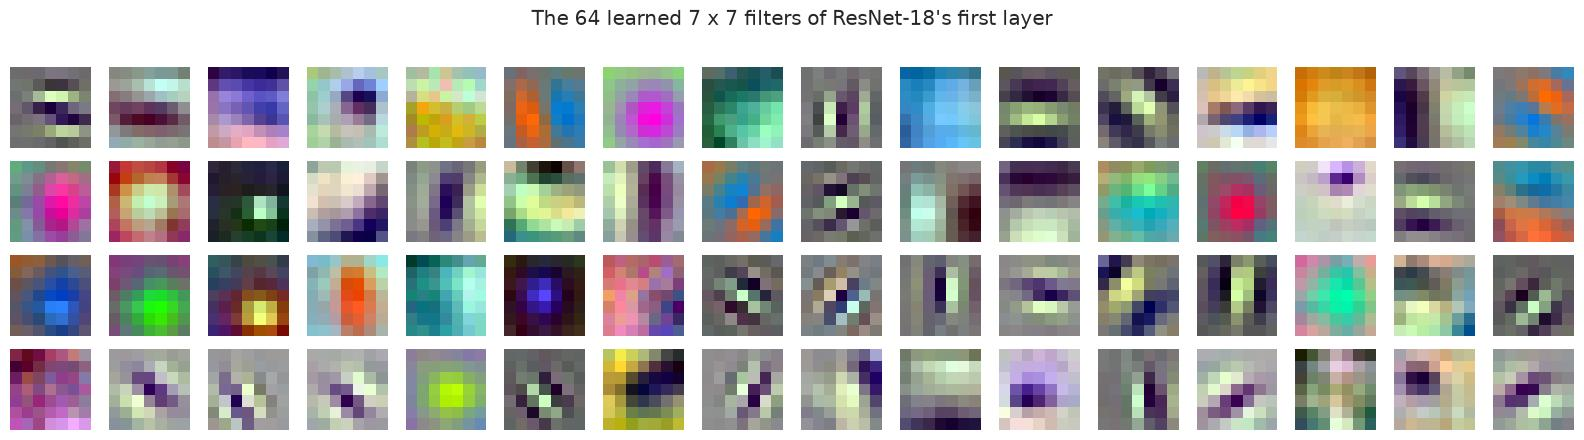

In [5]:
from torchvision.models import resnet18, ResNet18_Weights

weights = ResNet18_Weights.DEFAULT
cnn = resnet18(weights=weights, progress=False).eval()
first_filters = cnn.conv1.weight.detach()          # 64 learned kernels, each 3 colour channels x 7 x 7 pixels
print("First-layer filters:", tuple(first_filters.shape))

fig, axes = plt.subplots(4, 16, figsize=(16, 4.4))
for ax, kernel in zip(axes.flat, first_filters):
    k = kernel.permute(1, 2, 0).numpy()             # (3, 7, 7) -> (7, 7, 3) to show as a colour image
    ax.imshow((k - k.min()) / (k.max() - k.min()))
    ax.set_axis_off()
fig.suptitle("The 64 learned 7 x 7 filters of ResNet-18's first layer", y=1.0)
plt.tight_layout()
save_fig("nb3_01_resnet_filters")
plt.show()

Nobody designed these filters: they emerged from training. Many are **edge detectors** at different angles (black-and-white stripes, like our Sobel kernel in notebook 2) and others are **colour-contrast** detectors (green against magenta, blue against yellow). The network rediscovered the tools of classic computer vision, then learned to combine them.

Now let's pass a site photo through the network and look at what some channels respond to, at an early and at a deeper layer:

ResNet-18's guesses (ImageNet classes): torch (25%), stage (12%), lab coat (9%), whistle (6%), ocarina (3%)
Figure saved to figures/nb3_02_feature_maps.png


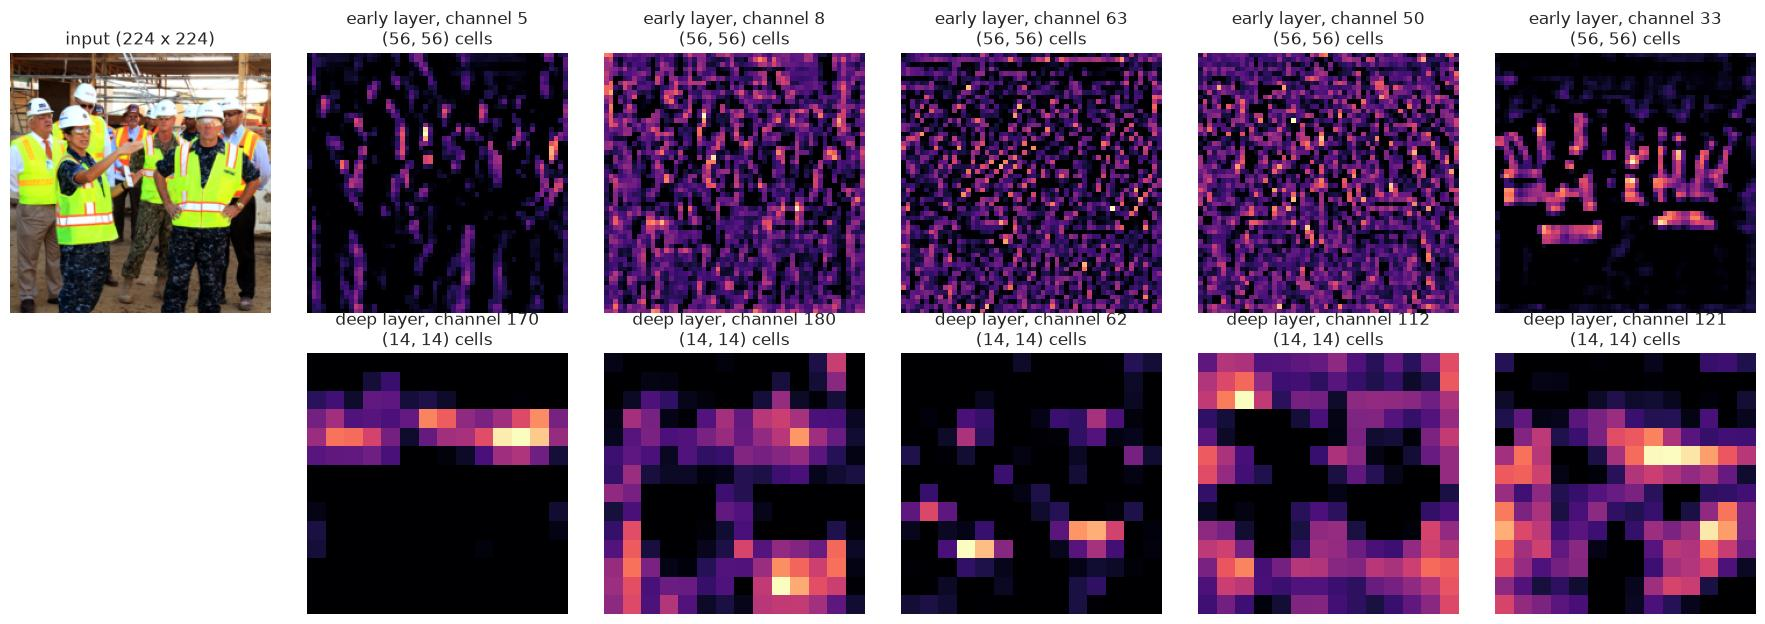

In [6]:
preprocess = weights.transforms()                    # resize, crop, scale to 0-1, normalise: what ResNet expects
image_rgb = cv2.cvtColor(site_visit, cv2.COLOR_BGR2RGB)
x = preprocess(torch.from_numpy(image_rgb).permute(2, 0, 1)).unsqueeze(0)    # (1, 3, 224, 224)

feature_maps = {}
cnn.layer1.register_forward_hook(lambda module, inp, out: feature_maps.update(early=out.detach()))
cnn.layer3.register_forward_hook(lambda module, inp, out: feature_maps.update(deep=out.detach()))
with torch.no_grad():
    top5 = cnn(x).softmax(dim=1).topk(5)
print("ResNet-18's guesses (ImageNet classes):",
      ", ".join(f"{weights.meta['categories'][i]} ({p:.0%})" for p, i in zip(top5.values[0], top5.indices[0])))

fig, axes = plt.subplots(2, 6, figsize=(18, 6.3))
axes[0, 0].imshow(np.clip(x[0].permute(1, 2, 0).numpy() * np.array(preprocess.std) + np.array(preprocess.mean), 0, 1))
axes[0, 0].set_title("input (224 x 224)")
axes[1, 0].set_visible(False)
for row, (name, maps) in enumerate(feature_maps.items()):
    strongest = maps[0].std(dim=(1, 2)).argsort(descending=True)[:5]        # the 5 channels with the most contrast
    for col, channel in enumerate(strongest, start=1):
        axes[row, col].imshow(maps[0, channel], cmap="magma")
        axes[row, col].set_title(f"{name} layer, channel {channel.item()}\n{tuple(maps.shape[2:])} cells")
for ax in axes.flat:
    ax.set_axis_off()
plt.tight_layout()
save_fig("nb3_02_feature_maps")
plt.show()

- **Early layer (56 × 56 cells):** the maps still look like the photo: they respond to **local patterns**, such as edges, stripes and colour contrasts. One of them (channel 33) lights up along horizontal bands at the height of the vests, where the reflective stripes are.
- **Deeper layer (14 × 14 cells):** each cell now "sees" a large part of the image, and the maps respond to **larger structures**. Channel 170, for instance, fires along the row of heads and helmets. The picture is coarser, but the meaning is richer.
- **The guesses** ("torch", "stage", "lab coat"…) are wrong in a revealing way: ImageNet has **no class** for construction workers, helmets or hi-vis vests, so the network names the nearest things it knows. A pretrained network has useful *features*, but it only speaks the *classes it was trained on*. That is why we fine-tune.

### Transfer learning

Training a CNN from scratch needs millions of labelled images and days of GPU time. **Transfer learning** reuses a network **pretrained** on a huge dataset: its early layers already know edges, textures and parts, which are useful for almost any image. We only **fine-tune** it on our task with a few thousand images. This is what we do with YOLO below: start from a model pretrained on the COCO dataset (330,000 images, 80 everyday classes) and fine-tune it on construction-site safety.

# 2. What a detector outputs: boxes, IoU and NMS

A detector returns, for each object it finds:
- a **box** (`x1, y1, x2, y2` in pixels, or centre + width + height),
- a **class** ("Hardhat", "Person"…),
- a **confidence** from 0 to 1 (how sure the model is).

To compare a predicted box with the true one we use **IoU** (*Intersection over Union*): the area where the two boxes overlap, divided by the area they cover together. 1 = perfect overlap, 0 = no overlap. A prediction usually counts as **correct** when its IoU with a true box of the same class is **at least 0.5**.

Figure saved to figures/nb3_03_iou.png


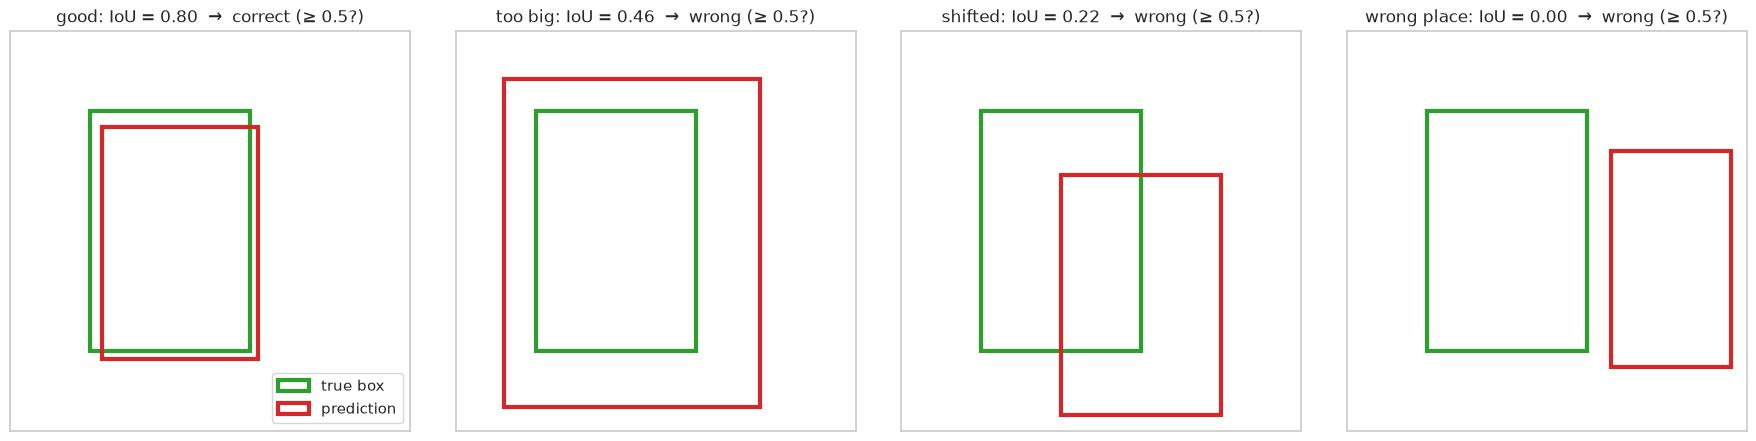

In [7]:
def iou(box_a, box_b):
    # Intersection over Union of two boxes given as (x1, y1, x2, y2)
    ix1, iy1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    ix2, iy2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0, ix2 - ix1) * max(0, iy2 - iy1)
    area_a = (box_a[2] - box_a[0]) * (box_a[3] - box_a[1])
    area_b = (box_b[2] - box_b[0]) * (box_b[3] - box_b[1])
    return intersection / (area_a + area_b - intersection)


truth = (100, 100, 300, 400)
examples = {"good": (115, 120, 310, 410), "too big": (60, 60, 380, 470), "shifted": (200, 180, 400, 480), "wrong place": (330, 150, 480, 420)}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.4))
for ax, (name, pred) in zip(axes, examples.items()):
    for box, color, label in [(truth, "tab:green", "true box"), (pred, "tab:red", "prediction")]:
        ax.add_patch(plt.Rectangle(box[:2], box[2] - box[0], box[3] - box[1], fill=False, lw=3, color=color, label=label))
    value = iou(truth, pred)
    ax.set_title(f"{name}: IoU = {value:.2f}  →  {'correct' if value >= 0.5 else 'wrong'} (≥ 0.5?)")
    ax.set_xlim(0, 500)
    ax.set_ylim(500, 0)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
axes[0].legend(loc="lower right")
plt.tight_layout()
save_fig("nb3_03_iou")
plt.show()

### Non-maximum suppression (NMS)

A detector looks at the image at many positions and scales, so it often proposes **several overlapping boxes for the same object**. **Non-maximum suppression** keeps the most confident box and removes the others that overlap it too much (IoU above a threshold, typically 0.5–0.7). YOLO does this for you; it is why you get one box per helmet and not ten. (The newest YOLO versions, like the YOLO26 we use, are trained to avoid duplicates in the first place, but the idea is the same.)

# 3. A pretrained YOLO: what it can and cannot see

**YOLO** (*You Only Look Once*) is a family of fast detectors that look at the whole image in one pass of a CNN. We use **YOLO26**, the current Ultralytics version, in the size **s** (small). Out of the box it is trained on **COCO**, 80 everyday classes. Let's try it on the site visit photo.

COCO classes (80): person, bicycle, car, motorcycle, airplane, bus, train, truck, boat, traffic light, fire hydrant, stop sign, parking meter, bench, bird, cat, dog, horse, sheep, cow, elephant, bear, zebra, giraffe, backpack, umbrella, handbag, tie, suitcase, frisbee ...
Any helmet, hard hat, vest or cone class? []

Detected: {'person': 10, 'tie': 1}
Figure saved to figures/nb3_04_coco_yolo.png


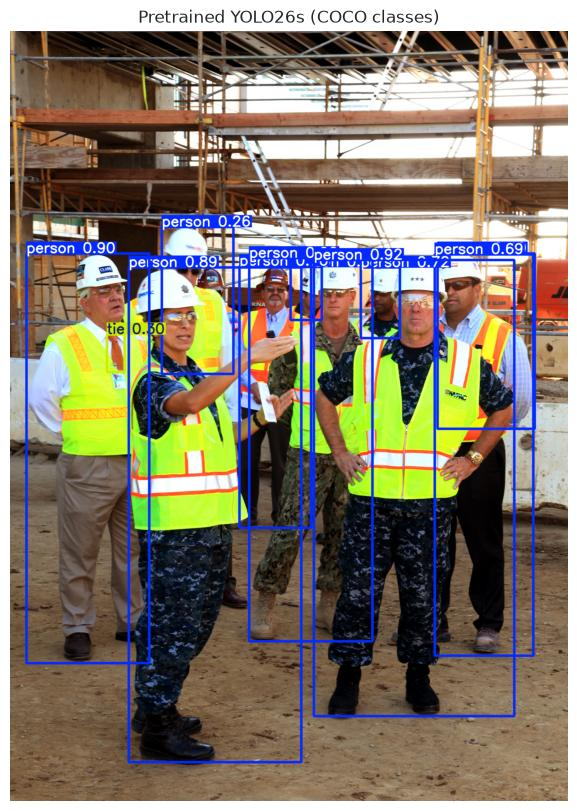

In [8]:
coco_model = YOLO(MODEL_DIR / "yolo26s.pt")           # downloaded the first time (about 20 MB)
print(f"COCO classes ({len(coco_model.names)}):", ", ".join(list(coco_model.names.values())[:30]), "...")
print("Any helmet, hard hat, vest or cone class?",
      [name for name in coco_model.names.values() if any(k in name for k in ["helmet", "hat", "vest", "cone"])])

result = coco_model.predict(site_visit, conf=0.25, device=DEVICE, verbose=False)[0]
found = pd.Series([result.names[int(c)] for c in result.boxes.cls]).value_counts()
print("\nDetected:", found.to_dict())

plt.figure(figsize=(8, 10))
show_image(result.plot(line_width=3, font_size=14), "Pretrained YOLO26s (COCO classes)")
save_fig("nb3_04_coco_yolo")
plt.show()

The pretrained model finds the **10 people** (and a tie!), but it **cannot** see helmets or vests: COCO simply has no such classes. A model can only detect what it was trained to detect. To get a safety detector we keep everything it has learned about images and people, and **fine-tune** it on labelled construction-site photos.

# 4. The dataset: construction site safety

## 4.1 The YOLO format

A YOLO dataset is a folder of images and a matching folder of **text files**, one per image, with one line per object:

```
css-data/
├── train/
│   ├── images/   photo_001.jpg  photo_002.jpg ...
│   └── labels/   photo_001.txt  photo_002.txt ...     ← same names, .txt
├── valid/  (images/, labels/)
└── test/   (images/, labels/)

photo_001.txt:
  class  x_centre  y_centre  width   height            ← all relative to the image size (0..1)
  5      0.4120    0.5521    0.1830  0.6200            ← a Person
  0      0.4050    0.2620    0.0610  0.0570            ← a Hardhat
```

A small **YAML** file tells YOLO where the folders are and what the class numbers mean:

In [9]:
data_config = {
    "path": str(DATASET_DIR.resolve()),
    "train": "train/images",
    "val": "valid/images",
    "test": "test/images",
    "names": dict(enumerate(CLASS_NAMES)),
}
DATA_YAML = DATA_DIR / "ppe_data.yaml"
DATA_YAML.write_text(yaml.safe_dump(data_config, sort_keys=False))
print(DATA_YAML.read_text())

example_label = sorted((DATASET_DIR / "train" / "labels").glob("*.txt"))[0]
print(f"{example_label.name}:\n{example_label.read_text()}")

path: /home/salvadorc/.cache/kagglehub/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/versions/3/css-data
train: train/images
val: valid/images
test: test/images
names:
  0: Hardhat
  1: Mask
  2: NO-Hardhat
  3: NO-Mask
  4: NO-Safety Vest
  5: Person
  6: Safety Cone
  7: Safety Vest
  8: machinery
  9: vehicle

-1670-_png_jpg.rf.0463edb430019e01ec79eed27a6349d6.txt:
0 0.0775416543763631 0.39375 0.09097043364502548 0.059375
0 0.01640625 0.41328125 0.0328125 0.1203125
3 0.04682291950167361 0.43671875 0.03935339149054773 0.05
3 0.09124054001317838 0.45625 0.05019998789975162 0.034375
5 0.16328125 0.4203125 0.3265625 0.178125
5 0.17578125 0.43046875 0.2859375 0.1578125
1 0.2578125 0.87109375 0.34375 0.2578125
2 0.25390625 0.5953125 0.3515625 0.171875
5 0.21484375 0.7546875 0.4296875 0.490625
1 0.7734375 0.8890625 0.4375 0.221875
2 0.78046875 0.6453125 0.4390625 0.175
5 0.71484375 0.76953125 0.5703125 0.4609375


## 4.2 Looking at the labels

Always look at the data before training. We draw the true boxes on a few training images:

Figure saved to figures/nb3_05_labels.png


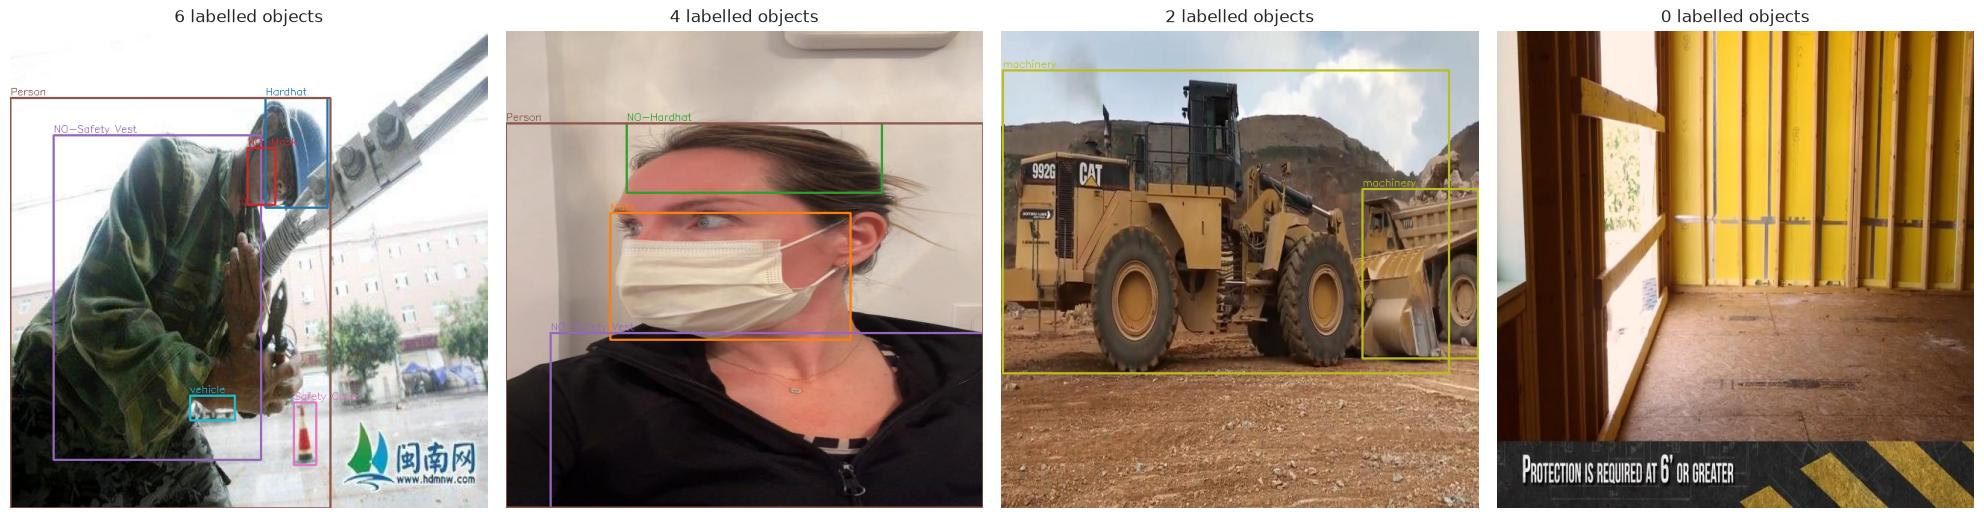

In [10]:
CLASS_COLORS = {i: tuple(int(255 * c) for c in plt.cm.tab10(i)[:3][::-1]) for i in range(len(CLASS_NAMES))}   # BGR


def read_labels(label_path):
    # Return a DataFrame with one row per box: class, cx, cy, w, h (relative)
    rows = [line.split() for line in Path(label_path).read_text().splitlines() if line.strip()]
    return pd.DataFrame(rows, columns=["cls", "cx", "cy", "w", "h"]).astype({"cls": int, "cx": float, "cy": float, "w": float, "h": float})


def draw_labels(image, labels, thickness=2):
    out = image.copy()
    h, w = out.shape[:2]
    for row in labels.itertuples():
        x1, y1 = int((row.cx - row.w / 2) * w), int((row.cy - row.h / 2) * h)
        x2, y2 = int((row.cx + row.w / 2) * w), int((row.cy + row.h / 2) * h)
        cv2.rectangle(out, (x1, y1), (x2, y2), CLASS_COLORS[row.cls], thickness)
        cv2.putText(out, CLASS_NAMES[row.cls], (x1, max(12, y1 - 4)), cv2.FONT_HERSHEY_SIMPLEX, 0.45, CLASS_COLORS[row.cls], 1)
    return out


test_images = sorted((DATASET_DIR / "test" / "images").glob("*.jpg"))
samples = [test_images[i] for i in (3, 17, 40, 66)]
fig, axes = plt.subplots(1, 4, figsize=(20, 5.3))
for ax, image_path in zip(axes, samples):
    labels = read_labels(DATASET_DIR / "test" / "labels" / f"{image_path.stem}.txt")
    show_image(draw_labels(cv2.imread(str(image_path)), labels), f"{len(labels)} labelled objects", ax)
plt.tight_layout()
save_fig("nb3_05_labels")
plt.show()

Figure saved to figures/nb3_06_class_counts.png


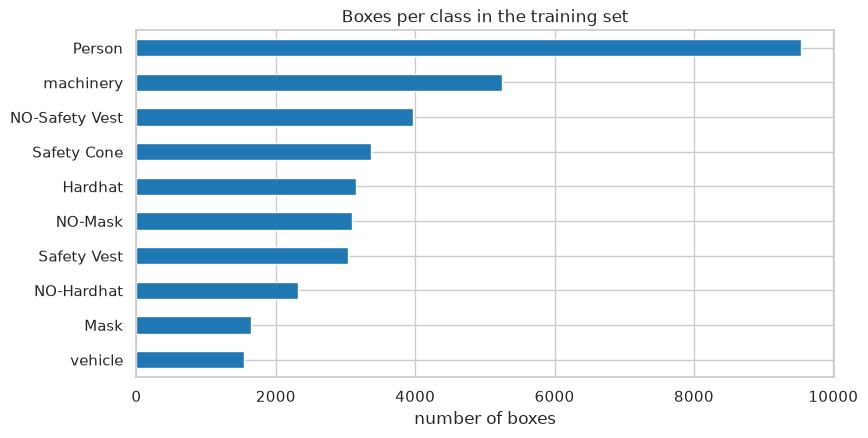

cls,Hardhat,Mask,NO-Hardhat,NO-Mask,NO-Safety Vest,Person,Safety Cone,Safety Vest,machinery,vehicle
train,3145,1651,2317,3097,3962,9532,3366,3033,5247,1545
valid,79,21,69,74,106,166,44,41,55,42
test,110,28,41,79,90,174,92,61,44,41


In [11]:
counts = {}
for split in ["train", "valid", "test"]:
    label_files = list((DATASET_DIR / split / "labels").glob("*.txt"))
    all_labels = pd.concat([read_labels(f) for f in label_files if f.stat().st_size > 0])
    counts[split] = all_labels["cls"].map(dict(enumerate(CLASS_NAMES))).value_counts()
counts = pd.DataFrame(counts).reindex(CLASS_NAMES).fillna(0).astype(int)

counts["train"].sort_values().plot.barh(figsize=(9, 4.5), color="tab:blue")
plt.title("Boxes per class in the training set")
plt.ylabel("")
plt.xlabel("number of boxes")
save_fig("nb3_06_class_counts")
plt.show()
counts.T

What to notice before training:
- **Splits:** 2,605 training images, but only **114 validation** and **82 test** images. Test results will be somewhat noisy: a few images more or less change the scores.
- **Augmented copies:** the dataset author already created several modified versions of each source photo (flips, crops, rotations, brightness changes, see the dataset's README), so the training set contains **fewer distinct photos** than its 2,605 files suggest.
- **Imbalance:** there are 9,532 `Person` boxes but only about 1,550–1,650 `vehicle` and `Mask` boxes. Classes with fewer examples are usually detected less well.
- **"NO-" classes:** `NO-Hardhat`, `NO-Mask` and `NO-Safety Vest` describe an **absence** (a head *without* a helmet). They are the most useful classes for a safety inspector, and the hardest to learn.
- **Mixed sources:** site photos, video frames, close-up selfies with face masks (from the COVID period), images with watermarks, and some **background images with no objects at all** (the fourth sample), which teach the model what is *not* an object.

# 5. Building your own dataset

For your own project (windows on facades, cracks, rebar, scaffolding…) you will need to **annotate** images yourself. The usual workflow:

```
 collect photos ─► annotate boxes ─► export in YOLO format ─► split train/val/test ─► train ─► check errors ─► add more photos where it fails
```

| Tool | Notes |
|---|---|
| [**Roboflow**](https://roboflow.com) | Web-based, free tier for public projects; annotation, augmentation, export to YOLO, and many public datasets (like ours) |
| [**CVAT**](https://www.cvat.ai) | Open source, web or self-hosted, very complete; good for teams |
| [**Label Studio**](https://labelstud.io) | Open source, many data types (images, text, audio) |
| [**makesense.ai**](https://www.makesense.ai) | Free, in the browser, nothing to install; good for a first small dataset |

**Labelling guidelines that make or break a model:**
- **Write down the class definitions** before you start ("Hardhat = a safety helmet on a head; helmets carried in the hand: not labelled") and stick to them. Inconsistent labels are the most common cause of bad models.
- **Tight boxes**, and label **every** instance of a class in every image: an unlabelled helmet teaches the model that helmets are background.
- **Variety beats quantity:** different sites, light, weather, distances, angles and cameras. 300 varied photos are worth more than 3,000 frames of the same video.
- **How many?** For fine-tuning a pretrained YOLO, a useful start is **100–300 images and a few hundred boxes per class**; add more for rare or small objects.
- **Split by source**, not by frame: frames from one video should all be in the same split, otherwise the test set is just a copy of the training set (leakage, Day 2).

💡 **Tip:** SAM (section 10) can turn your boxes into pixel masks automatically, which makes a segmentation dataset almost free once you have boxes.

# 6. Where to train: three tiers

Training a detector is the heaviest computation of the course. You have three options:

| Tier | Where | Model | Training setup | Indicative time and cost (October 2026) |
|---|---|---|---|---|
| **local** | Your laptop: CPU, Apple GPU or a small NVIDIA GPU | YOLO26**n** (nano, 2.4 M parameters) | 25% of the training images, 10 epochs | 10–30 min on a CPU (measured: 20 min on a 20-core laptop CPU, test mAP50 0.54), a few min on a GPU; free |
| **free_cloud** | **Google Colab** (free T4 GPU) or **Kaggle Notebooks** (free T4/P100, about 30 GPU-hours per week) | YOLO26**s** (small, about 10 M parameters) | All images, 40 epochs | 33 min on a laptop RTX 4050 (the model in this notebook, test mAP50 0.78); similar or slower on a free T4; free |
| **rented** | A cloud GPU rented by the hour: **RunPod**, **Vast.ai**, **Lambda**, **Hugging Face Jobs**… | YOLO26**m**/**l** (medium/large) | All images, 100+ epochs | 1–3 h on an RTX 4090 or A100, roughly $0.35–1.50 per hour: a few € in total |

Prices and free quotas change often: check the provider's page before you start.

### How to use each tier

**Local.** Nothing to set up: run this notebook.
- **With an NVIDIA GPU**, it trains with the `free_cloud` settings.
- **Without one** (most laptops, including Macs), training a detector is slow, so by default the notebook **downloads the course model** ([iaac-maai/day4-example-ppe-detector](https://huggingface.co/iaac-maai/day4-example-ppe-detector), trained with the `free_cloud` settings) and uses it for the rest of the notebook. To train the small `local` model on your CPU anyway (about 20 minutes), set `TRAIN = True` below.

**Google Colab.** Upload this notebook, choose *Runtime → Change runtime type → T4 GPU*, run the `%pip` cell, then everything else. Free sessions stop after a few hours or when idle, so save `best.pt` to Google Drive or download it as soon as training ends.

**Kaggle Notebooks.** *Create → New notebook → File → Import notebook*, then *Settings → Accelerator → GPU T4*. The dataset can be attached directly (*Add data → "construction site safety"*). Kaggle shows your remaining weekly GPU hours in the sidebar.

**Rented GPU** (e.g. RunPod):
1. Create an account and add a small credit (e.g. €10).
2. Start a "pod" with a PyTorch template and a GPU (an RTX 4090 is plenty for YOLO).
3. Open its Jupyter interface, upload this notebook (or `git clone` your repository), run `pip install ultralytics kagglehub`.
4. Set `TRAINING_TIER = "rented"` and run.
5. Download `runs/ppe_rented/weights/best.pt`.
6. ⚠️ **Stop and delete the pod.** You pay for every hour it runs, even when idle. This is the most common (and most expensive) mistake.

In [12]:
TIERS = {
    "local":      {"model": "yolo26n.pt", "fraction": 0.25, "epochs": 10,  "imgsz": 640, "batch": 8},
    "free_cloud": {"model": "yolo26s.pt", "fraction": 1.0,  "epochs": 40,  "imgsz": 640, "batch": 16},
    "rented":     {"model": "yolo26m.pt", "fraction": 1.0,  "epochs": 100, "imgsz": 640, "batch": 32},
}

TRAINING_TIER = None      # None = automatic; or set "local", "free_cloud" or "rented" yourself
TRAIN = None              # None = automatic: train only if there is an NVIDIA GPU; True / False to decide yourself
RETRAIN = False           # True = train again even if a trained model already exists
COURSE_MODEL = "iaac-maai/day4-example-ppe-detector"    # used when we do not train

if TRAINING_TIER is None:
    TRAINING_TIER = "free_cloud" if DEVICE == "cuda" else "local"
if TRAIN is None:
    TRAIN = DEVICE == "cuda"
settings = TIERS[TRAINING_TIER]
print(f"Training tier: {TRAINING_TIER} -> {settings}")
print("Plan:", "train (or reuse an earlier training)" if TRAIN else f"download the course model {COURSE_MODEL}")

Training tier: free_cloud -> {'model': 'yolo26s.pt', 'fraction': 1.0, 'epochs': 40, 'imgsz': 640, 'batch': 16}
Plan: train (or reuse an earlier training)


# 7. Fine-tuning YOLO

One call does everything: it loads the pretrained weights, replaces the 80-class COCO "head" with a new 10-class head, and trains on our images. During training YOLO also applies **data augmentation** (random flips, colour changes, scaling and "mosaics" of 4 images) so the model sees more variety than the raw dataset contains.

| Setting | Meaning |
|---|---|
| `epochs` | Passes over the whole training set |
| `imgsz` | Images are resized to this size (pixels); larger = small objects easier to see, but slower |
| `batch` | Images per training step (limited by GPU memory) |
| `fraction` | Share of the training images used (the `local` tier uses 25% to be fast) |
| `patience` | Stop early if the validation score does not improve for this many epochs (notebook 1, early stopping) |

In [13]:
run_name = f"ppe_{TRAINING_TIER}"
best_weights = RUNS_DIR / run_name / "weights" / "best.pt"

results_csv = RUNS_DIR / run_name / "results.csv"
model_source = TRAINING_TIER                       # where the model comes from: a tier, or "course"

if best_weights.exists() and not RETRAIN:
    print(f"Reusing the trained model in {best_weights} (set RETRAIN = True to train again)")
elif not TRAIN:
    # No GPU: download the detector trained for the course (20 MB) and its training log
    course_dir = MODEL_DIR / "course_ppe_detector"
    best_weights = Path(hf_hub_download(repo_id=COURSE_MODEL, filename="model.pt", local_dir=course_dir))
    results_csv = Path(hf_hub_download(repo_id=COURSE_MODEL, filename="results.csv", local_dir=course_dir))
    model_source = "course"
    print(f"No training on this computer: using the course model from https://huggingface.co/{COURSE_MODEL}")
else:
    start = time.time()
    model = YOLO(MODEL_DIR / settings["model"])
    model.train(
        data=str(DATA_YAML), epochs=settings["epochs"], imgsz=settings["imgsz"], batch=settings["batch"],
        fraction=settings["fraction"], device=0 if DEVICE == "cuda" else DEVICE, seed=RANDOM_STATE,
        project=str(RUNS_DIR), name=run_name, exist_ok=True, patience=100, workers=4, verbose=False,
    )
    print(f"Training took {(time.time() - start) / 60:.0f} minutes")

detector = YOLO(best_weights)
print("Classes:", detector.names)

Reusing the trained model in /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/runs/ppe_free_cloud/weights/best.pt (set RETRAIN = True to train again)
Classes: {0: 'Hardhat', 1: 'Mask', 2: 'NO-Hardhat', 3: 'NO-Mask', 4: 'NO-Safety Vest', 5: 'Person', 6: 'Safety Cone', 7: 'Safety Vest', 8: 'machinery', 9: 'vehicle'}


Figure saved to figures/nb3_07_training_curves.png


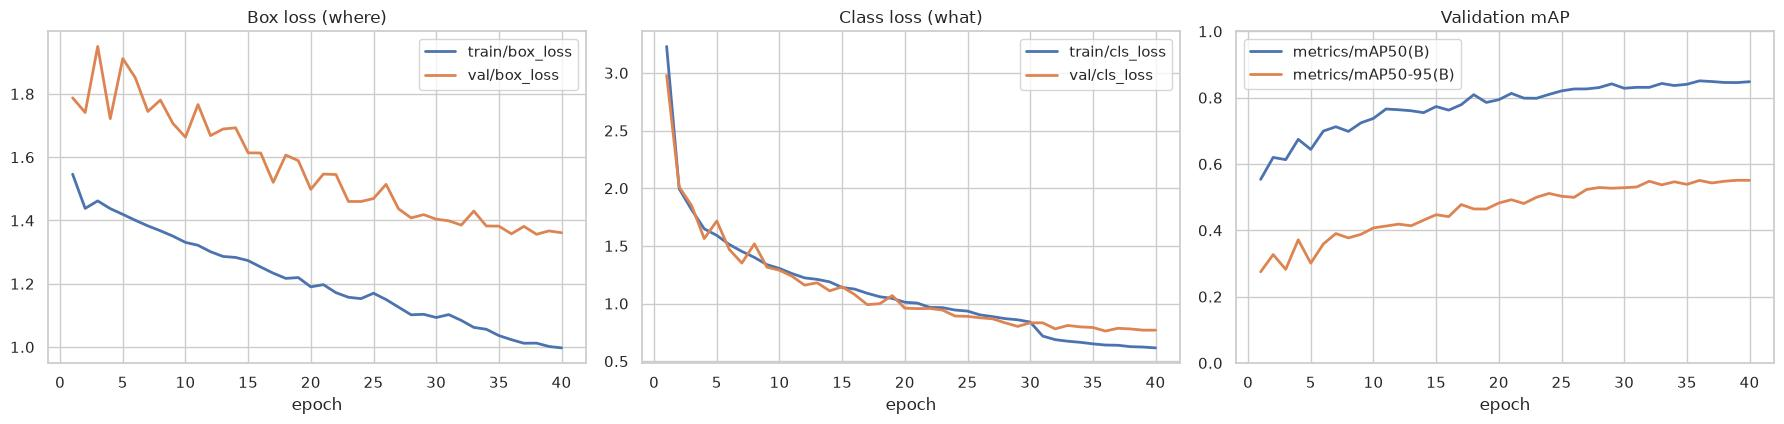

,epoch,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B)
0,1,0.639,0.519,0.554,0.275
10,11,0.864,0.686,0.766,0.413
20,21,0.904,0.723,0.813,0.492
30,31,0.923,0.736,0.831,0.531
39,40,0.914,0.762,0.848,0.551


In [14]:
history = pd.read_csv(results_csv)          # the training log, one row per epoch
history.columns = history.columns.str.strip()

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
history.plot(x="epoch", y=["train/box_loss", "val/box_loss"], ax=axes[0], lw=2, title="Box loss (where)")
history.plot(x="epoch", y=["train/cls_loss", "val/cls_loss"], ax=axes[1], lw=2, title="Class loss (what)")
history.plot(x="epoch", y=["metrics/mAP50(B)", "metrics/mAP50-95(B)"], ax=axes[2], lw=2, title="Validation mAP")
axes[2].set_ylim(0, 1)
plt.tight_layout()
save_fig("nb3_07_training_curves")
plt.show()
rows_to_show = sorted({0, len(history) // 4, len(history) // 2, 3 * len(history) // 4, len(history) - 1})   # works for any number of epochs
history[["epoch", "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]].iloc[rows_to_show].round(3)

- **Transfer learning works fast:** after a single epoch the validation mAP50 is already **0.55**: the pretrained COCO features (people, shapes, colours) transfer immediately. It reaches **0.77 after 11 epochs** and **0.85 after 40**.
- **No overfitting:** the validation losses keep falling with the training losses until the end, and mAP is still creeping up slowly, so more epochs (the rented tier) would gain a little more.
- The sudden drop of the class loss at **epoch 31** is not magic: for the last 10 epochs YOLO switches off its "mosaic" augmentation (`close_mosaic=10`), so the training images become easier.
- **For reference:** the dataset author trained a YOLOv8**n** for 100 epochs and reported a validation mAP50 of 0.81 (mAP50-95 0.51). Our YOLO26**s**, a larger and newer model, reaches **0.85 (0.55) in 40 epochs**, in about **33 minutes** on a laptop RTX 4050.

# 8. Evaluation: precision, recall and mAP

The Day 2 metrics, adapted to boxes. A prediction is a **true positive** if it has the right class and IoU ≥ 0.5 with a true box; otherwise it is a **false positive**; a true box with no matching prediction is a **false negative**.

| Metric | Question | Day 2 equivalent |
|---|---|---|
| **Precision** | Of the boxes the model drew, how many are correct? | Precision |
| **Recall** | Of the real objects, how many did the model find? | Recall |
| **AP** (average precision) | Precision averaged over all recall levels, i.e. over all confidence thresholds: one number per class | Area under the precision-recall curve |
| **mAP50** | AP averaged over the classes, with "correct" = IoU ≥ 0.5 | |
| **mAP50-95** | The same, averaged over IoU thresholds 0.5, 0.55 … 0.95: also rewards **precise** boxes | |

The **test set** has stayed locked during training (validation was used to watch the training). We evaluate on it **once**:

In [15]:
test_metrics = detector.val(data=str(DATA_YAML), split="test", device=0 if DEVICE == "cuda" else DEVICE,
                            project=str(RUNS_DIR), name=f"{run_name}_test", exist_ok=True, verbose=False, plots=True)

per_class = pd.DataFrame({
    "boxes in test set": counts["test"],
    "precision": test_metrics.box.p,
    "recall": test_metrics.box.r,
    "AP50": test_metrics.box.ap50,
    "AP50-95": test_metrics.box.ap,
}, index=CLASS_NAMES).round(3)
print(f"TEST SET: mAP50 = {test_metrics.box.map50:.3f}, mAP50-95 = {test_metrics.box.map:.3f}, "
      f"precision = {test_metrics.box.mp:.3f}, recall = {test_metrics.box.mr:.3f}")
per_class.sort_values("AP50")

Ultralytics 8.4.190 🚀 Python-3.12.3 torch-2.14.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4050 Laptop GPU, 6140MiB)
YOLO26s summary (fused): 120 layers, 9,469,050 parameters, 0 gradients, 20.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2942.5±823.5 MB/s, size: 47.1 KB)
val: Scanning /home/salvadorc/.cache/kagglehub/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow/versions/3/css-data/test/labels.cache... 82 images, 8 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 82/82 28.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.9it/s 2.1s
                   all         82        760      0.877      0.732       0.78        0.5
Speed: 2.6ms preprocess, 14.2ms inference, 0.0ms loss, 0.9ms postprocess per image
Results saved to /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/runs/ppe_free_cloud_test
TEST SET: mAP50 = 0.780, mAP50-95 = 0.500, precision = 0.877, recall = 0.732


,boxes in test set,precision,recall,AP50,AP50-95
Safety Cone,92,0.768,0.478,0.519,0.240
NO-Hardhat,41,0.787,0.585,0.564,0.341
Mask,28,0.948,0.750,0.752,0.548
vehicle,41,0.823,0.679,0.756,0.481
NO-Mask,79,0.880,0.696,0.800,0.351
NO-Safety Vest,90,0.970,0.767,0.826,0.528
Person,174,0.869,0.802,0.859,0.591
machinery,44,0.876,0.841,0.875,0.691
Safety Vest,61,0.867,0.820,0.892,0.615
Hardhat,110,0.980,0.898,0.958,0.613


Figure saved to figures/nb3_08_confusion_matrix.png


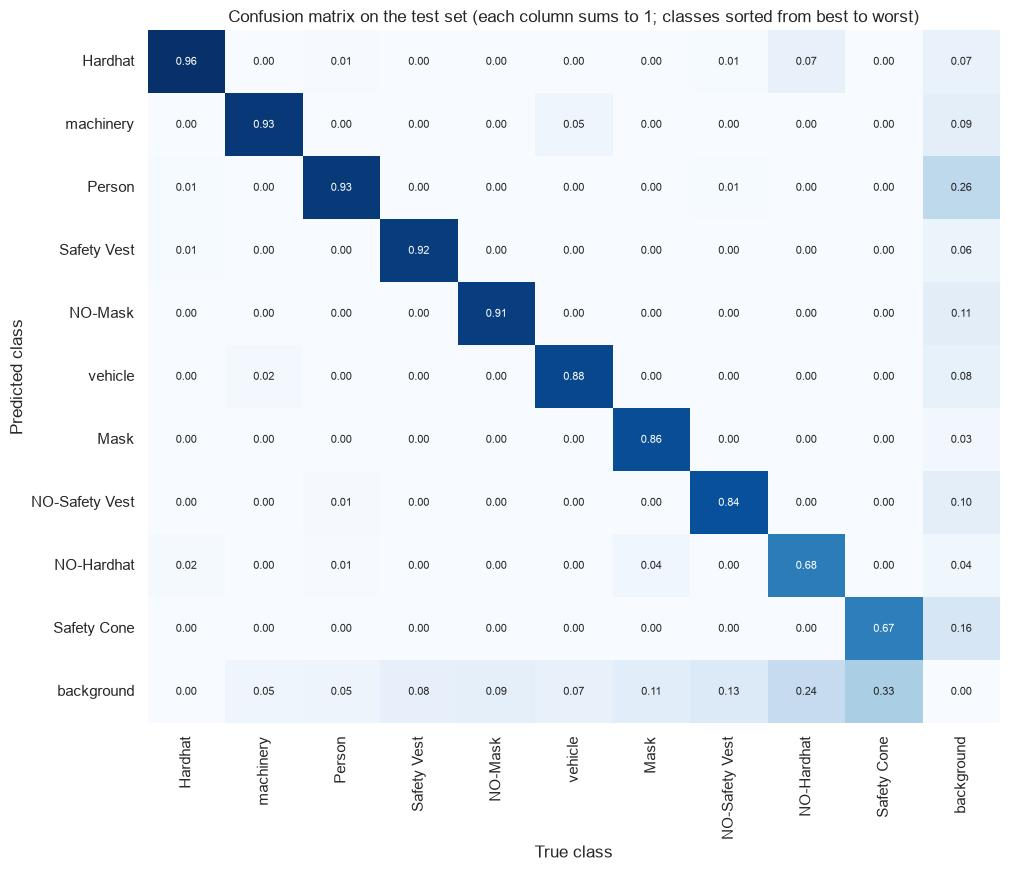

In [16]:
confusion = test_metrics.confusion_matrix.matrix            # rows: predicted, columns: true (last = background)
labels = CLASS_NAMES + ["background"]
normalised = confusion / confusion.sum(axis=0, keepdims=True).clip(min=1)

# Sort the classes from best to worst (the diagonal: share of each class found correctly); "background" stays last
order = list(np.argsort(-np.diag(normalised)[:-1], kind="stable")) + [len(CLASS_NAMES)]
normalised = normalised[np.ix_(order, order)]
labels = [labels[i] for i in order]

plt.figure(figsize=(11, 9))
sns.heatmap(normalised, annot=True, fmt=".2f", cmap="Blues", xticklabels=labels, yticklabels=labels, cbar=False,
            annot_kws={"size": 8})
plt.xlabel("True class")
plt.ylabel("Predicted class")
plt.title("Confusion matrix on the test set (each column sums to 1; classes sorted from best to worst)")
save_fig("nb3_08_confusion_matrix")
plt.show()

**On the test set:** mAP50 = **0.78**, mAP50-95 = **0.50**, precision **0.88**, recall **0.73**. This is lower than on the validation set (0.85): the test set is small (82 images) and was never used to make any choice, so this is the honest number to report.

**Per class**, the average hides big differences:
- **Easy:** `Hardhat` (AP50 0.96), `Safety Vest` (0.89), `machinery` (0.88), `Person` (0.86): large, frequent, distinctive objects.
- **Hard:** `Safety Cone` (0.52), often **small and far away**, and `NO-Hardhat` (0.56), defined by an **absence**.

**The confusion matrix** (classes sorted from best to worst along the diagonal) shows the type of mistake: the model rarely confuses one class with another, it mostly **misses objects** (the bottom row, "background"): **33% of the cones** and **24% of the heads without helmets** are not detected at all, and another 7% of the bare heads are taken for helmets. Its false alarms (the right-hand column) are mostly `Person` (26% of them) and `Safety Cone` (16%). Thanks to the sorting, the pattern is visible at a glance: the bottom row grows towards the right, so the weakest classes are weak mainly because they are **missed**.

💡 **Tip:** the diagonal (share found with the right label) and AP50 rank the classes slightly differently, because AP50 also counts false alarms and averages over all confidence thresholds. Look at both.

🤔 **Think about it:** the two weakest classes, bare heads and cones, are exactly the ones a safety inspector cares about most. A good overall mAP would hide this: always report **per-class** results.

# 9. Inference: a site safety report, and the video

## 9.1 Predictions vs the truth

Figure saved to figures/nb3_09_predictions.png


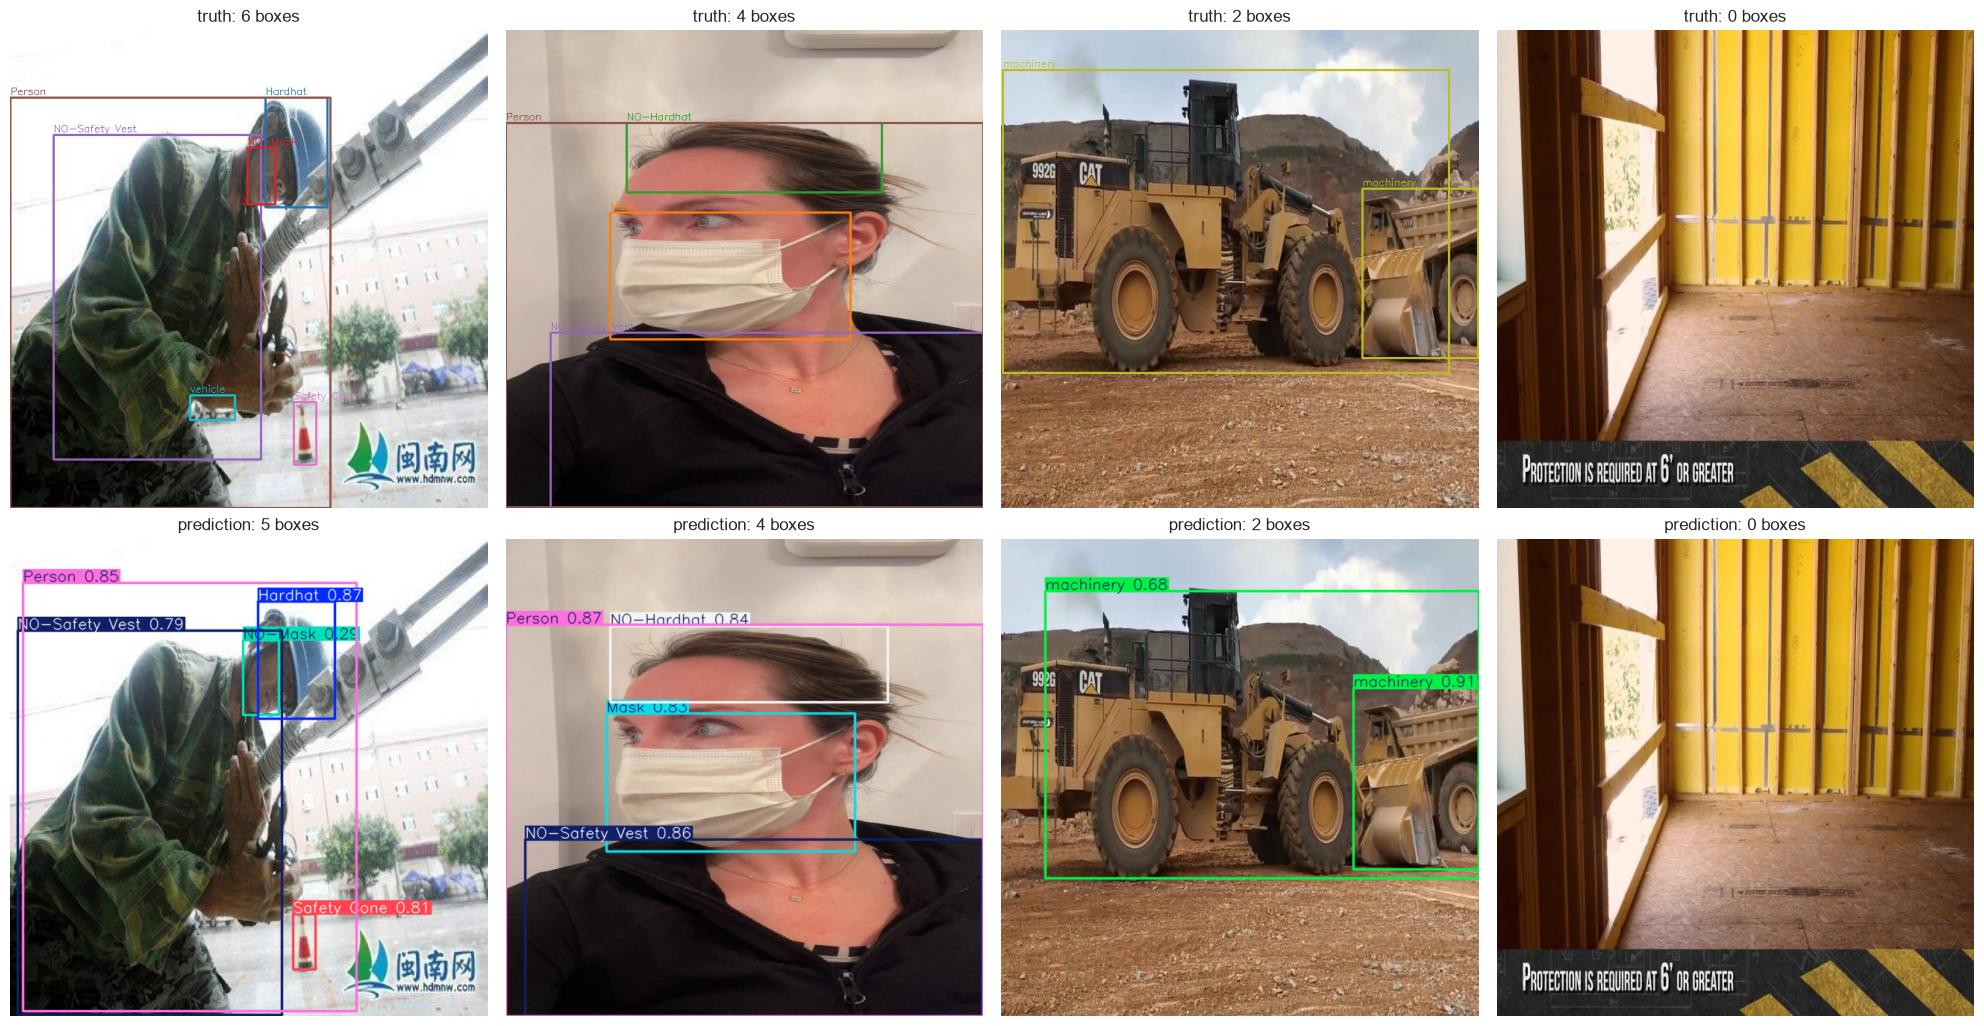

In [17]:
fig, axes = plt.subplots(2, 4, figsize=(20, 10.5))
for col, image_path in enumerate(samples):
    image = cv2.imread(str(image_path))
    labels = read_labels(DATASET_DIR / "test" / "labels" / f"{image_path.stem}.txt")
    show_image(draw_labels(image, labels), f"truth: {len(labels)} boxes", axes[0, col])
    prediction = detector.predict(image, conf=0.25, device=DEVICE, verbose=False)[0]
    show_image(prediction.plot(line_width=2, font_size=9), f"prediction: {len(prediction.boxes)} boxes", axes[1, col])
plt.tight_layout()
save_fig("nb3_09_predictions")
plt.show()

## 9.2 Choosing the confidence threshold

Every prediction comes with a confidence, and **we** choose the cut-off. A low threshold finds more objects (higher **recall**) but adds false alarms (lower **precision**); a high threshold does the opposite. As on Day 2, the right choice depends on the **cost of each mistake**.

For a safety inspector, the important classes are **NO-Hardhat** and **NO-Safety Vest**. Missing a worker without a helmet is worse than a false alarm that a person checks in a few seconds, so we favour **recall**. Let's measure precision and recall on the test set at several thresholds, matching predictions to true boxes with IoU ≥ 0.5 (section 2):

Figure saved to figures/nb3_10_threshold_sweep.png


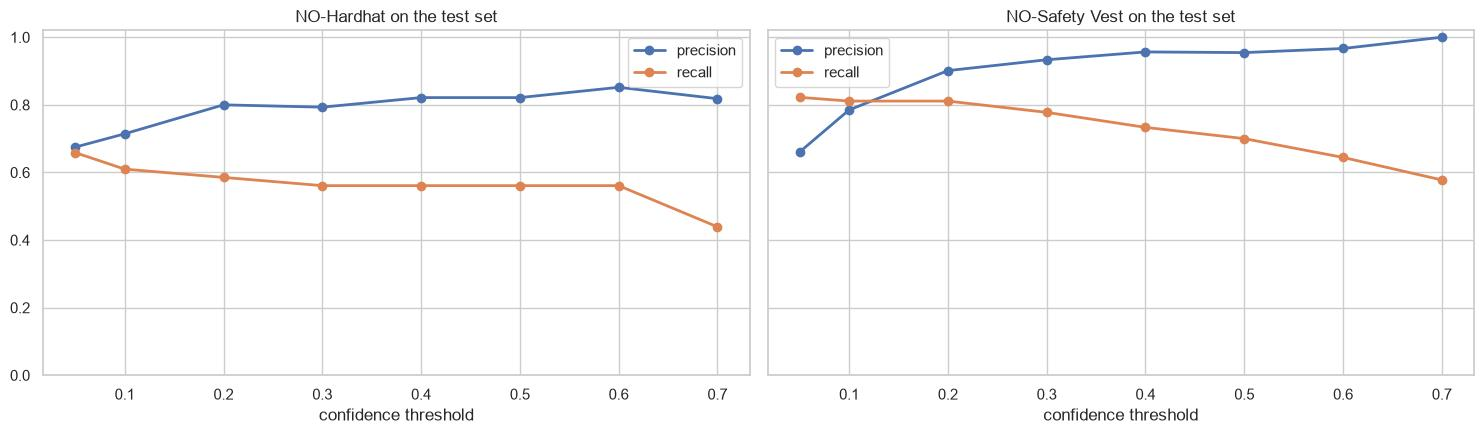

precision  recall  found  false alarms  missed
class          threshold                                                
NO-Hardhat     0.05            0.68    0.66     27            13      14
               0.10            0.71    0.61     25            10      16
               0.20            0.80    0.59     24             6      17
               0.30            0.79    0.56     23             6      18
               0.40            0.82    0.56     23             5      18
               0.50            0.82    0.56     23             5      18
               0.60            0.85    0.56     23             4      18
               0.70            0.82    0.44     18             4      23
NO-Safety Vest 0.05            0.66    0.82     74            38      16
               0.10            0.78    0.81     73            20      17
               0.20            0.90    0.81     73             8      17
               0.30            0.93    0.78     70             5      20
               0.40            0.96    0.73     66             3      24
               0.50            0.95    0.70     63             3      27
               0.60            0.97    0.64     58             2      32
               0.70            1.00    0.58     52             0      38

In [18]:
def match_counts(pred_boxes, true_boxes, iou_threshold=0.5):
    # Greedy matching (most confident first): returns (true positives, false positives, false negatives)
    matched, tp = set(), 0
    for p in pred_boxes:
        best = max(((iou(p, t), j) for j, t in enumerate(true_boxes) if j not in matched), default=(0, None))
        if best[0] >= iou_threshold:
            matched.add(best[1])
            tp += 1
    return tp, len(pred_boxes) - tp, len(true_boxes) - tp


# Predict once at a very low threshold, then filter at different thresholds
test_predictions = {}
for image_path in test_images:
    result = detector.predict(str(image_path), conf=0.05, device=DEVICE, verbose=False)[0]
    test_predictions[image_path.stem] = (result.boxes.xyxy.cpu().numpy(), result.boxes.cls.cpu().numpy().astype(int),
                                         result.boxes.conf.cpu().numpy(), result.orig_shape)

rows = []
for class_name in ["NO-Hardhat", "NO-Safety Vest"]:
    k = CLASS_NAMES.index(class_name)
    for threshold in [0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]:
        tp = fp = fn = 0
        for stem, (boxes, classes, confidences, (h, w)) in test_predictions.items():
            labels = read_labels(DATASET_DIR / "test" / "labels" / f"{stem}.txt")
            labels = labels[labels["cls"] == k]
            truth = [((r.cx - r.w / 2) * w, (r.cy - r.h / 2) * h, (r.cx + r.w / 2) * w, (r.cy + r.h / 2) * h) for r in labels.itertuples()]
            keep = (classes == k) & (confidences >= threshold)
            order = np.argsort(-confidences[keep])
            counts_ = match_counts(boxes[keep][order], truth)
            tp, fp, fn = tp + counts_[0], fp + counts_[1], fn + counts_[2]
        rows.append({"class": class_name, "threshold": threshold, "precision": tp / max(tp + fp, 1),
                     "recall": tp / max(tp + fn, 1), "found": tp, "false alarms": fp, "missed": fn})
sweep = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (class_name, part) in zip(axes, sweep.groupby("class")):
    ax.plot(part["threshold"], part["precision"], marker="o", lw=2, label="precision")
    ax.plot(part["threshold"], part["recall"], marker="o", lw=2, label="recall")
    ax.set_title(f"{class_name} on the test set")
    ax.set_xlabel("confidence threshold")
    ax.set_ylim(0, 1.02)
    ax.legend()
plt.tight_layout()
save_fig("nb3_10_threshold_sweep")
plt.show()
sweep.set_index(["class", "threshold"]).round(2)

- **NO-Safety Vest** behaves as the textbook says: raising the threshold from 0.05 to 0.7 lifts precision from 0.66 to **1.00** but drops recall from 0.82 to 0.58. A threshold around **0.2** is a good compromise for an inspection tool: **90% precision and 81% recall** (73 of 90 found, 8 false alarms).
- **NO-Hardhat** is limited by the model, not by the threshold: even at 0.05 it finds only **27 of 41** bare heads (recall 0.66). Lowering the threshold further only adds false alarms. The fix is **more and better training data** for this class (more bare heads, from more angles and distances), not a different setting.

This is the Day 2 lesson again: the threshold moves you **along** the precision-recall trade-off; only a better model moves the whole curve.

## 9.3 A site safety report

From detections to a decision: for each photo, count the people and the missing-PPE detections, and flag the photos that need a human check. We use a threshold of **0.3**, favouring recall (section 9.2).

In [19]:
REPORT_THRESHOLD = 0.3
report = []
for stem, (boxes, classes, confidences, _) in test_predictions.items():
    keep = confidences >= REPORT_THRESHOLD
    found = pd.Series([CLASS_NAMES[c] for c in classes[keep]]).value_counts()
    report.append({"image": stem[:30], "people": found.get("Person", 0), "no helmet": found.get("NO-Hardhat", 0),
                   "no vest": found.get("NO-Safety Vest", 0), "helmets": found.get("Hardhat", 0), "vests": found.get("Safety Vest", 0)})
report = pd.DataFrame(report)
report["check"] = np.where((report["no helmet"] + report["no vest"]) > 0, "⚠ check", "ok")

print(f"{len(report)} test photos: {(report['check'] != 'ok').sum()} flagged for a check, "
      f"{report['people'].sum()} people, {report['no helmet'].sum()} 'no helmet' and {report['no vest'].sum()} 'no vest' detections")
report.sort_values(["no helmet", "no vest"], ascending=False).head(8)

82 test photos: 36 flagged for a check, 169 people, 29 'no helmet' and 75 'no vest' detections


,image,people,no helmet,no vest,helmets,vests,check
56,thumbnail-ba5c72edb320b49a69e8,12,9,9,0,0,⚠ check
36,class2_145_jpg.rf.b8ed5a5357ee,2,2,2,0,0,⚠ check
59,youtube-126_jpg.rf.786824e90da,2,2,2,0,0,⚠ check
27,NX_img_177_jpg.rf.c03709e5fadf,3,1,3,2,0,⚠ check
34,class1_150_jpg.rf.5995dce34d38,2,1,2,1,0,⚠ check
53,maksssksksss17_png_jpg.rf.f685,1,1,2,0,0,⚠ check
11,2009_000059_jpg.rf.50e8398a37e,1,1,1,0,0,⚠ check
16,IMG_0871_MOV-12_jpg.rf.36858a9,1,1,1,0,0,⚠ check


## 9.4 The same video as notebook 2

Now the real comparison: the same two clips, processed by the fine-tuned detector. We also switch on **tracking** (`model.track`, ByteTrack), which links detections across frames and gives every person an ID, so we can count **distinct** people instead of detections per frame.

Processed 1394 frames in 28 s; saved data/output_yolo.mp4 (66 MB)
Figure saved to figures/nb3_11_video_frames.png


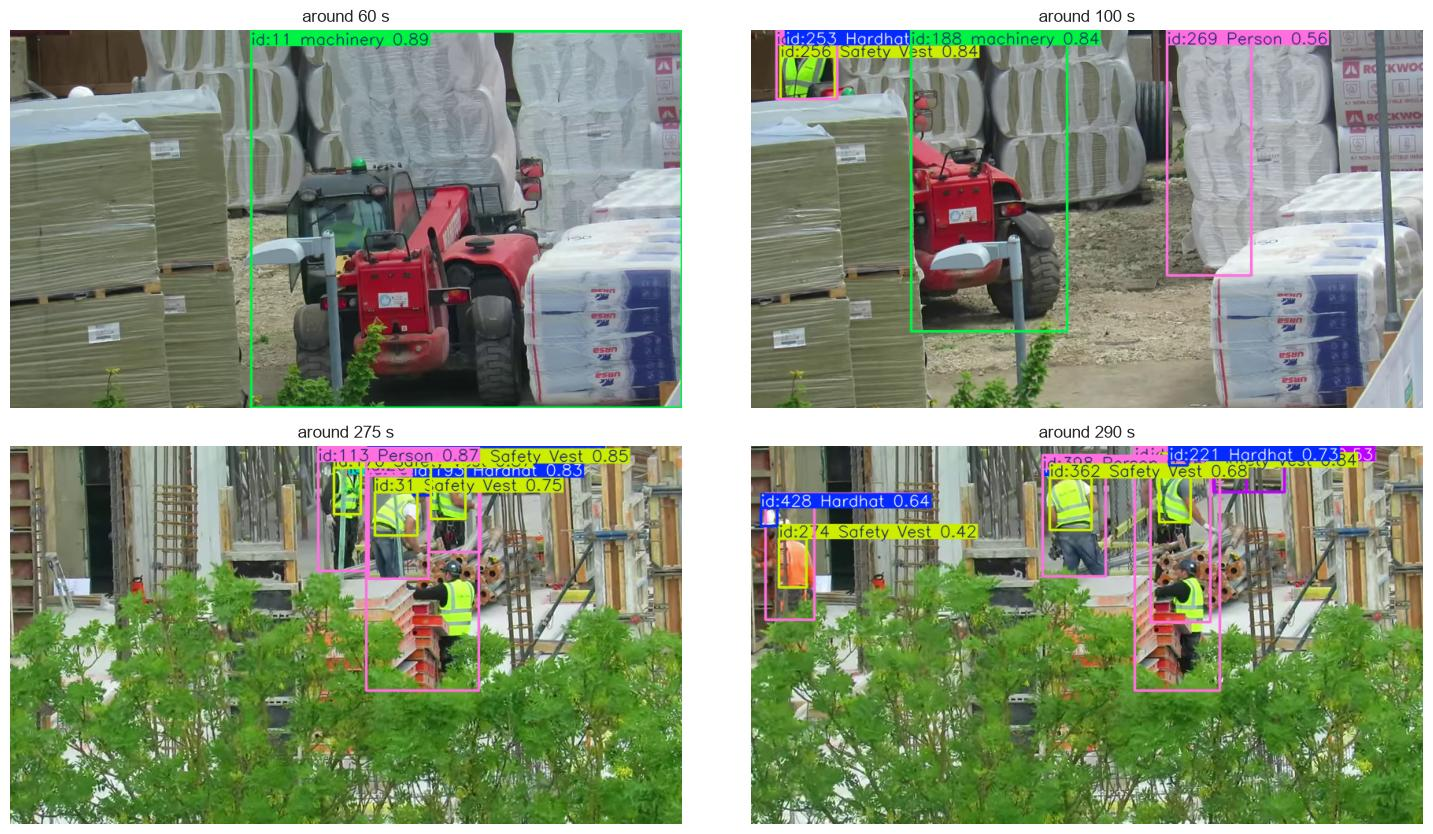

In [20]:
CLIPS = [(50, 105), (262, 300)]
STEP = 2
output_path = DATA_DIR / "output_yolo.mp4"

capture = cv2.VideoCapture(str(VIDEO_PATH))
fps, width, height = capture.get(cv2.CAP_PROP_FPS), int(capture.get(3)), int(capture.get(4))
writer = cv2.VideoWriter(str(output_path), cv2.VideoWriter_fourcc(*"mp4v"), fps / STEP, (width, height))

log, examples = [], {}
start = time.time()
for clip_number, (clip_start, clip_end) in enumerate(CLIPS):
    capture.set(cv2.CAP_PROP_POS_MSEC, clip_start * 1000)
    tracker_model = YOLO(best_weights)                    # a fresh tracker for every clip
    frame_number = 0
    while True:
        ok, frame = capture.read()
        seconds = capture.get(cv2.CAP_PROP_POS_MSEC) / 1000
        if not ok or seconds > clip_end:
            break
        frame_number += 1
        if frame_number % STEP:
            continue
        result = tracker_model.track(frame, conf=REPORT_THRESHOLD, persist=True, tracker="bytetrack.yaml",
                                     device=DEVICE, verbose=False)[0]
        classes = [CLASS_NAMES[int(c)] for c in result.boxes.cls]
        ids = result.boxes.id.int().tolist() if result.boxes.id is not None else [None] * len(classes)
        annotated = result.plot(line_width=2, font_size=9)
        writer.write(annotated)
        log.append({"clip": clip_number, "second": seconds, **pd.Series(classes).value_counts().to_dict(),
                    "person ids": [i for i, c in zip(ids, classes) if c == "Person" and i is not None]})
        for t in (60, 100, 275, 290):
            if t not in examples and seconds >= t:
                examples[t] = annotated
capture.release()
writer.release()
log = pd.DataFrame(log).fillna(0)
print(f"Processed {len(log)} frames in {time.time() - start:.0f} s; saved {output_path} ({output_path.stat().st_size / 1e6:.0f} MB)")

fig, axes = plt.subplots(2, 2, figsize=(15, 8.5))
for ax, (t, image) in zip(axes.flat, examples.items()):
    show_image(image, f"around {t} s", ax)
plt.tight_layout()
save_fig("nb3_11_video_frames")
plt.show()

In [21]:
summary = {}
for clip_number, part in log.groupby("clip"):
    columns = [c for c in ["Person", "Hardhat", "Safety Vest", "NO-Hardhat", "NO-Safety Vest", "machinery", "vehicle"] if c in part]
    per_frame = part[columns].mean().round(2)
    per_frame["distinct person IDs"] = len({i for ids in part["person ids"] for i in ids})
    summary[f"clip {CLIPS[clip_number][0]}-{CLIPS[clip_number][1]} s"] = per_frame
pd.DataFrame(summary).rename_axis("average per frame (except IDs)")

,clip 50-105 s,clip 262-300 s
average per frame (except IDs),,
Person,0.94,3.73
Hardhat,0.48,2.54
Safety Vest,0.27,2.68
NO-Hardhat,0.00,0.06
NO-Safety Vest,0.07,0.38
machinery,1.05,0.07
vehicle,0.00,0.32
distinct person IDs,35.00,52.00


Comparing with the rule-based pipeline of notebook 2 on the same frames:
- **Speed:** 1,394 frames in about 27 s on the GPU (rules: about 45 s on the CPU).
- **Telehandler (first clip):** detected as `machinery` in practically every frame (1.05 per frame on average), **including when it turns round**, where SIFT lost it. The detector learned what machinery looks like from many examples; it does not need to have seen *this* machine from *this* side.
- **Workers (second clip):** on average **3.7 people**, 2.5 helmets and 2.7 vests per frame, and the worker in the **orange vest** is now found, which the yellow colour rule could not do. `NO-Hardhat` is almost never reported (0.06 per frame), which matches the footage: everyone wears a helmet.
- **Mistakes remain:** around 100 s an insulation stack is briefly taken for a `Person`.

⚠️ **Watch out: tracking.** The tracker reports **35 and 52 "distinct" person IDs**, although only a handful of people appear. Every time a worker disappears behind the leaves or another worker, or is small and blurry, the tracker loses him and starts a **new ID** when he reappears (we also skip every second frame, which makes it harder). Counting unique people with a tracker needs tuning, a steady view and checking: never report raw ID counts as head counts.

# 10. Segment Anything (SAM)

**SAM** (*Segment Anything Model*, Meta AI) is a **foundation model** for segmentation: trained on 11 million images and 1 billion masks, it can outline **any** object, without fine-tuning, when you tell it **where** to look with a **prompt**: a point, a box, or nothing at all ("segment everything").

| | YOLO (detection) | SAM (segmentation) |
|---|---|---|
| Output | Boxes + **class names** | Pixel-exact **masks**, but **no class names** |
| Needs training on your classes? | Yes (fine-tuning) | No: zero-shot |
| Speed | Real time | Slower (the image encoder is heavy) |
| Typical use | "Find all helmets" | "Outline exactly this object" |

They complement each other: **YOLO says what and where, SAM draws the exact outline.**

We use **MobileSAM**, a small and fast version (40 MB) that runs on a laptop CPU; the larger **SAM 2.1** models (`sam2.1_t.pt` … `sam2.1_l.pt`) are more accurate and also work on video.

In [22]:
sam = SAM(MODEL_DIR / "mobile_sam.pt")


def overlay_masks(image, masks, colors=None, alpha=0.5):
    # Paint each mask in a colour on top of the image, and outline it
    out = image.copy()
    for k, mask in enumerate(masks):
        color = colors[k] if colors else tuple(int(255 * c) for c in plt.cm.tab10(k % 10)[:3][::-1])
        out[mask] = (out[mask] * (1 - alpha) + np.array(color) * alpha).astype(np.uint8)
        contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(out, contours, -1, color, 2)
    return out


def sam_masks(result):
    return [] if result.masks is None else list(result.masks.data.cpu().numpy().astype(bool))

## 10.1 Prompts: a point and a box

Figure saved to figures/nb3_12_sam_prompts.png


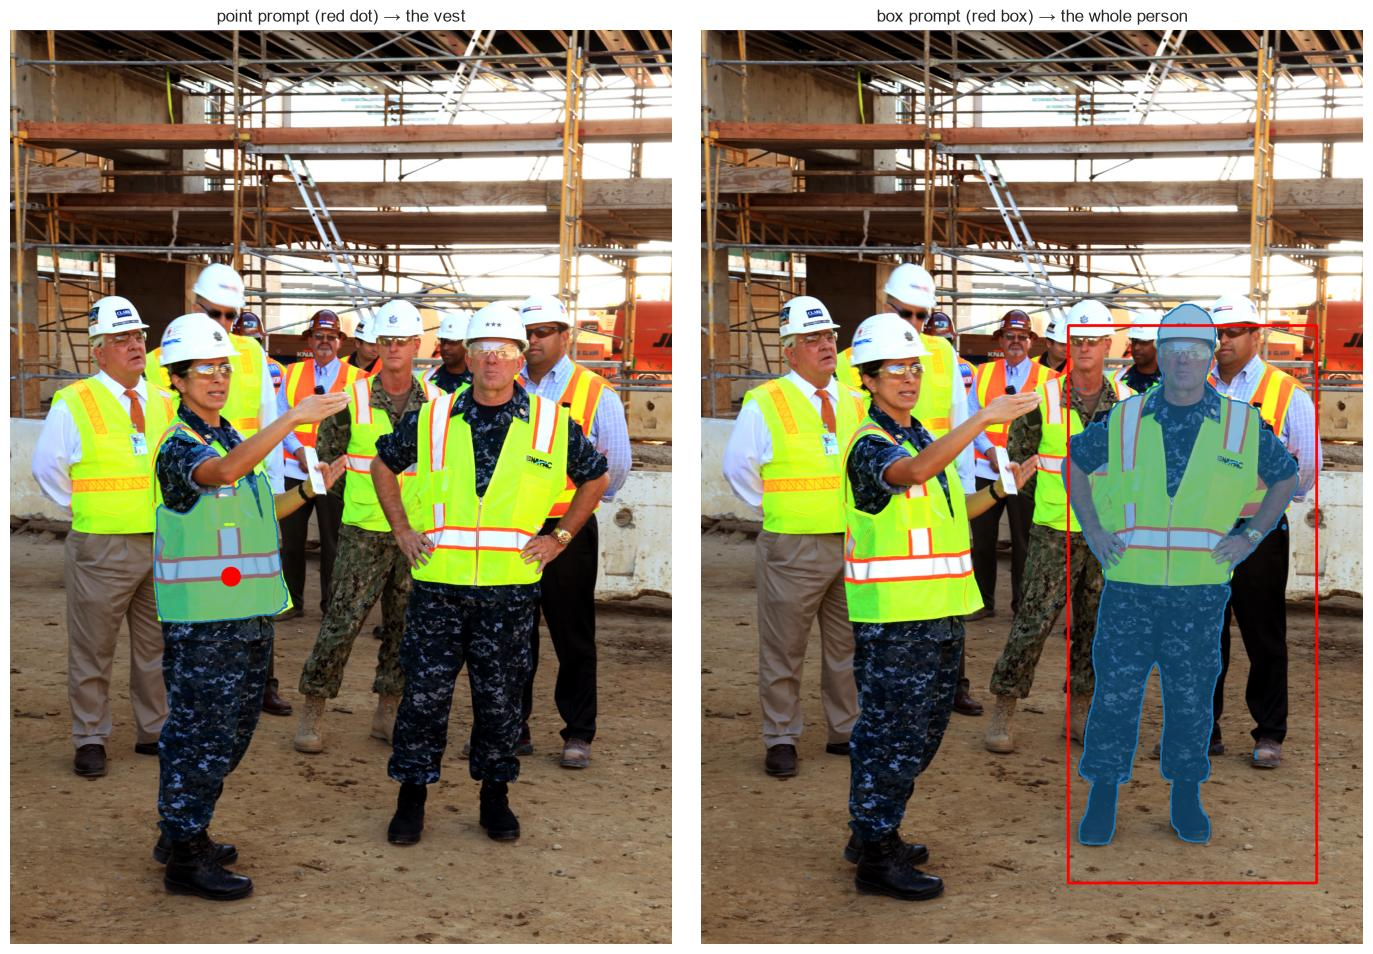

In [23]:
point = [400, 990]                        # a point on the vest of the woman in front (x, y in pixels)
box = [665, 535, 1115, 1545]              # a box around the man on the right (x1, y1, x2, y2)

point_result = sam.predict(site_visit, points=[point], labels=[1], device=DEVICE, verbose=False)[0]
box_result = sam.predict(site_visit, bboxes=[box], device=DEVICE, verbose=False)[0]

fig, axes = plt.subplots(1, 2, figsize=(14, 9.5))
image_point = overlay_masks(site_visit, sam_masks(point_result))
cv2.circle(image_point, tuple(point), 18, (0, 0, 255), -1)
show_image(image_point, "point prompt (red dot) → the vest", axes[0])
image_box = overlay_masks(site_visit, sam_masks(box_result))
cv2.rectangle(image_box, tuple(box[:2]), tuple(box[2:]), (0, 0, 255), 4)
show_image(image_box, "box prompt (red box) → the whole person", axes[1])
plt.tight_layout()
save_fig("nb3_12_sam_prompts")
plt.show()

The **point** on the vest gives the **vest**: SAM returns the smallest object that clearly contains the point. The **box** gives the **whole person** inside it. Prompts are how you tell SAM what "the object" is: a point can be ambiguous (vest? person? group?), a box much less so.

## 10.2 YOLO → SAM: from boxes to exact outlines

Chain the two models: the fine-tuned YOLO finds the safety equipment, and its boxes become SAM prompts. Masks also give **areas in pixels**, e.g. how much of a worker's torso is covered by a hi-vis vest.

Figure saved to figures/nb3_13_yolo_sam.png


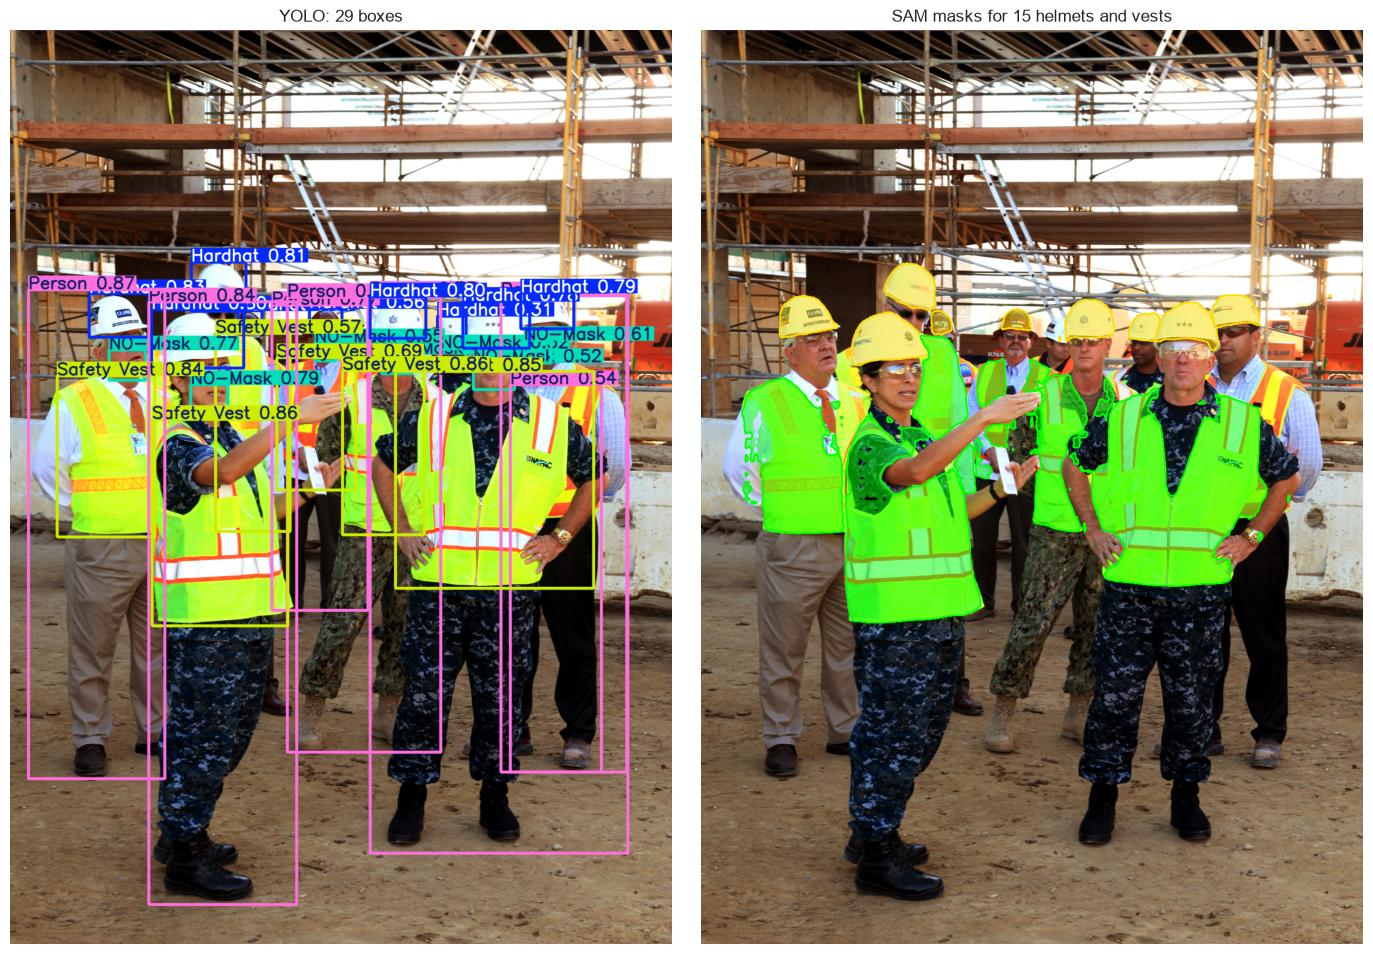

,box area (px),mask area (px),mask / box
class,,,
Hardhat,7225.399902,4619.78,0.71
Safety Vest,68695.468750,36657.17,0.49


In [24]:
detections = detector.predict(site_visit, conf=0.3, device=DEVICE, verbose=False)[0]
keep = [CLASS_NAMES[int(c)] in ("Hardhat", "Safety Vest") for c in detections.boxes.cls]
boxes = detections.boxes.xyxy.cpu().numpy()[keep]
names = [CLASS_NAMES[int(c)] for c, k in zip(detections.boxes.cls, keep) if k]

masks = sam_masks(sam.predict(site_visit, bboxes=boxes, device=DEVICE, verbose=False)[0])
colors = [(0, 220, 255) if n == "Hardhat" else (0, 255, 0) for n in names]       # helmets yellow, vests green (BGR)
areas = pd.DataFrame({"class": names, "box area (px)": [(b[2] - b[0]) * (b[3] - b[1]) for b in boxes],
                      "mask area (px)": [int(m.sum()) for m in masks]})
areas["mask / box"] = (areas["mask area (px)"] / areas["box area (px)"]).round(2)

fig, axes = plt.subplots(1, 2, figsize=(14, 9.5))
show_image(detections.plot(line_width=3, font_size=12), f"YOLO: {len(detections.boxes)} boxes", axes[0])
show_image(overlay_masks(site_visit, masks, colors), f"SAM masks for {len(masks)} helmets and vests", axes[1])
plt.tight_layout()
save_fig("nb3_13_yolo_sam")
plt.show()
areas.groupby("class")[["box area (px)", "mask area (px)", "mask / box"]].mean().round(2)

YOLO found 29 objects; the 15 helmets and vests among them became SAM prompts, and SAM traced each one exactly. The table shows why masks matter: a **helmet** fills about **71%** of its box, but a **vest** only **49%**: the box also contains arms, the gap at the front and the people behind. Areas, coverage and shapes should be measured on **masks**, not boxes. In a real project this could become, for example, the share of each worker's torso covered by a hi-vis vest, or the exact area of a material stock on site.

## 10.3 Auto-annotation: from boxes to a segmentation dataset

If you have **box labels** (or a detector), SAM can generate **mask labels** for you. Ultralytics' `auto_annotate` runs a detector and SAM on a folder of images and writes YOLO **segmentation** label files (polygons instead of boxes): the fastest way to build a segmentation dataset. Let's try it on 4 test images.


image 1/4 /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/data/auto_annotate/images/003357_jpg.rf.9867f91e88089bb68dc95947d5116d14.jpg: 640x640 1 Hardhat, 1 NO-Safety Vest, 1 Person, 1 Safety Cone, 26.7ms
image 2/4 /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/data/auto_annotate/images/IMG_0871_mp4-11_jpg.rf.432092b53ebeb84f4b9b27b40343c9aa.jpg: 640x640 1 Mask, 1 NO-Hardhat, 1 NO-Safety Vest, 1 Person, 9.8ms
image 3/4 /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/data/auto_annotate/images/construction-2-_mp4-162_jpg.rf.efad5f15524c736fe03b9c9936adc481.jpg: 640x640 2 machinerys, 8.0ms
image 4/4 /home/salvadorc/maai_2026/term_1/ai-methods-1-2026/Day_4/docs/data/auto_annotate/images/youtube-253_jpg.rf.5ad0a2d701e20141940508b809584856.jpg: 640x640 (no detections), 14.3ms
Speed: 1.1ms preprocess, 14.7ms inference, 1.0ms postprocess per image at shape (1, 3, 640, 640)
Figure saved to figures/nb3_14_auto_annotate.png


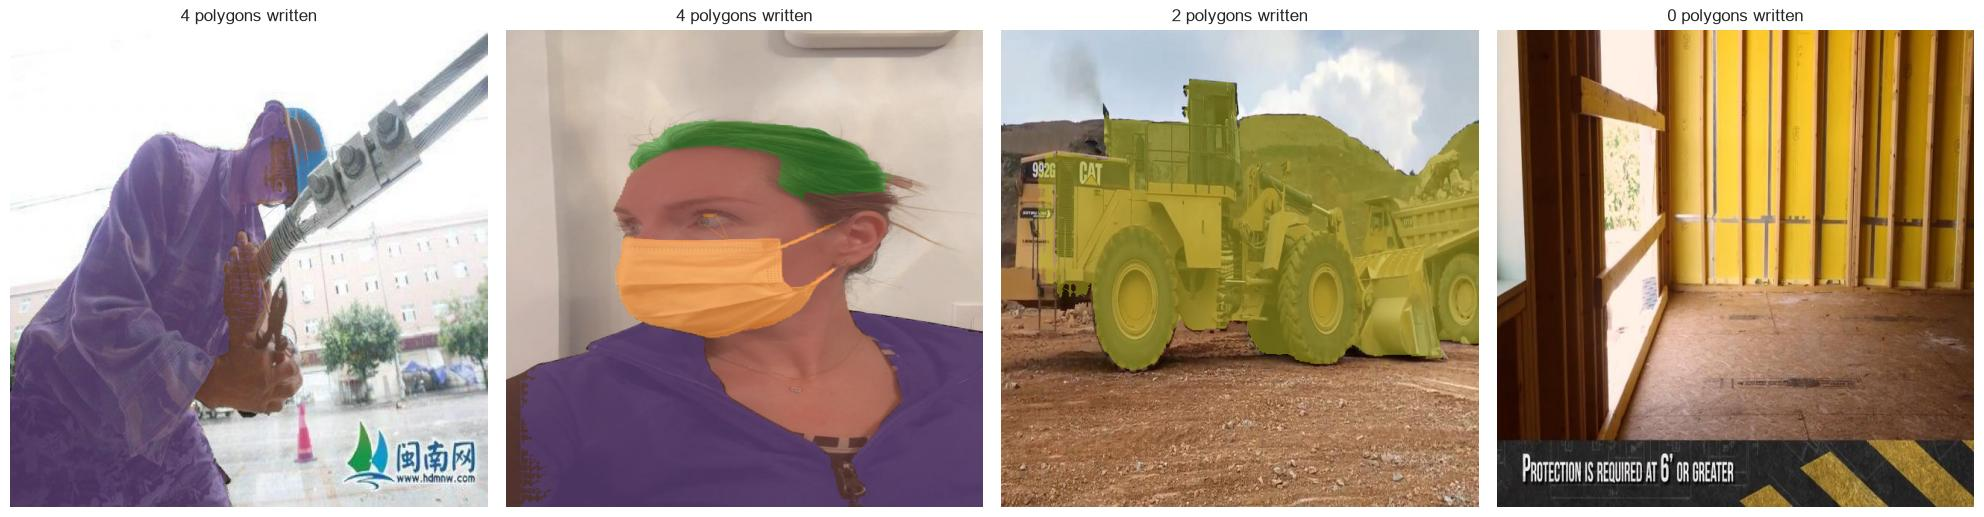

First lines of a segmentation label file (class, then x y pairs of the polygon):
0 0.504687488079071 0.21250000596046448 0.504687488079071 0.21718749403953552 0.504687488079071 0.212500005960 ...
5 0.5562499761581421 0.47187501192092896 0.5546875 0.47187501192092896 0.5531250238418579 0.4703125059604645 0 ...
6 0.609375 0.7828124761581421 0.606249988079071 0.785937488079071 0.606249988079071 0.7875000238418579 0.60468 ...


In [25]:
from ultralytics.data.annotator import auto_annotate

auto_dir = DATA_DIR / "auto_annotate"
images_dir = auto_dir / "images"
images_dir.mkdir(parents=True, exist_ok=True)
for image_path in samples:
    shutil.copy(image_path, images_dir / image_path.name)

auto_annotate(data=str(images_dir), det_model=str(best_weights), sam_model=str(MODEL_DIR / "mobile_sam.pt"),
              device=DEVICE, conf=0.3, output_dir=str(auto_dir / "labels"))

fig, axes = plt.subplots(1, 4, figsize=(20, 5.3))
for ax, image_path in zip(axes, samples):
    image = cv2.imread(str(image_path))
    h, w = image.shape[:2]
    label_file = auto_dir / "labels" / f"{image_path.stem}.txt"
    label_lines = label_file.read_text().splitlines() if label_file.exists() else []   # no detections = no file
    out = image.copy()
    for line in label_lines:
        values = line.split()
        polygon = (np.array(values[1:], dtype=float).reshape(-1, 2) * [w, h]).astype(np.int32)
        color = CLASS_COLORS[int(values[0])]
        cv2.fillPoly(out, [polygon], color)
    show_image(cv2.addWeighted(image, 0.5, out, 0.5, 0), f"{len(label_lines)} polygons written", ax)
plt.tight_layout()
save_fig("nb3_14_auto_annotate")
plt.show()
print("First lines of a segmentation label file (class, then x y pairs of the polygon):")
written = sorted((auto_dir / "labels").glob("*.txt"))
print("\n".join(line[:110] + " ..." for line in written[0].read_text().splitlines()[:3]))

⚠️ **Watch out:** auto-annotations inherit the detector's mistakes (a missed helmet gets no mask) and SAM's (a mask that leaks into the background). Always **review and correct** them in an annotation tool before training on them. They save time; they do not replace checking.

### 10.4 Limits of SAM
- **No class names:** SAM outlines things, it does not say what they are. Pair it with a detector, or with a text-prompted model (Ultralytics' **YOLOE** accepts prompts like "helmet").
- **Speed:** the image encoder is heavy; MobileSAM and SAM 2.1-tiny are the laptop-friendly versions.
- **Ambiguous prompts:** a point can mean the vest, the person or the group.
- **Fine-tuning SAM** on your own masks is possible but needs a large GPU (the rented tier) and is beyond this course.

# 11. Saving and sharing the model

The trained weights are in `best.pt` (the epoch with the best validation mAP). Copy them somewhere permanent:

In [26]:
final_weights = MODEL_DIR / f"ppe_detector_{model_source}.pt"
shutil.copy(best_weights, final_weights)
print(f"Saved {final_weights} ({final_weights.stat().st_size / 1e6:.0f} MB)")

# Reload and use it, as anyone would
reloaded = YOLO(final_weights)
print("Reloaded model classes:", list(reloaded.names.values()))

Saved models/ppe_detector_free_cloud.pt (20 MB)
Reloaded model classes: ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask', 'NO-Safety Vest', 'Person', 'Safety Cone', 'Safety Vest', 'machinery', 'vehicle']


**Other formats.** To run the model outside Python (in a web page, on a phone, in Grasshopper or Unity) export it, for example to **ONNX**: `YOLO(final_weights).export(format="onnx")`. Ultralytics installs the extra packages it needs the first time.

**Publishing.** Exactly like Days 2 and 3: put `best.pt` and a **model card** (classes, training data and licence, metrics per class, limitations, intended use) in a Hugging Face repository with the `hf` CLI. For a detector, the model card should include the **per-class AP** and the **confidence threshold** you recommend, and say clearly what the model must **not** be used for.

⚠️ **Watch out:** `.pt` files are large (20–100 MB). Keep them out of GitHub (`*.pt` in `.gitignore`) and share them through Hugging Face.

# 12. Summary

### Which vision tool, when?

| You need… | Use | Training data needed |
|---|---|---|
| To process images with known, controlled conditions (rectify, threshold, measure, count simple colours) | **OpenCV rules** (notebook 2) | None |
| One label for the whole image ("damaged / not damaged") | **Classification** (a fine-tuned CNN) | Hundreds of labelled images |
| What **and where**: count and locate objects | **Detection** (YOLO) | Hundreds of images with **boxes** |
| Exact outlines, areas, shapes | **Segmentation** (YOLO-seg, or SAM + a detector) | Images with **masks** (or SAM to make them) |
| Outline **any** object on demand, no training | **SAM** with point/box prompts | None |

### Checklist for a detection project
- [ ] Classes **defined in writing**; labels consistent, tight, complete.
- [ ] Varied data; train / validation / test **split by source** (no frames of one video in two splits).
- [ ] Start from a **pretrained** model and fine-tune; choose the tier that fits your time and budget.
- [ ] Watch the training and validation curves; evaluate **once** on the test set.
- [ ] Report **per-class** AP, not only the mean: rare and small classes hide behind a good average.
- [ ] Choose the **confidence threshold** from the cost of each mistake.
- [ ] Look at the errors on images and video, not just the numbers.

### Ethics and privacy
Site safety detectors watch **people at work**. Before deploying one: inform the workers, use it to **improve safety** (where are helmets often missing? which tasks?), not to punish individuals; minimise what you store (blur faces, keep counts instead of footage); and remember that the model makes mistakes, so a human must check before any decision. In the EU, video monitoring of workers is regulated by the GDPR and national labour law, and the AI Act sets extra rules for AI used to monitor or evaluate workers.

# 13. Your turn

**Exercise 1 – The local tier.** Set `TRAINING_TIER = "local"`, `TRAIN = True` and `RETRAIN = True` and train the nano model on 25% of the data. Compare its test mAP and per-class AP with the model in this notebook. Which classes suffer most from the smaller model and the smaller dataset?

**Exercise 2 – Your threshold.** Extend the threshold sweep of section 9.2 to the **Person** and **Hardhat** classes. Which threshold would you choose for a weekly safety report, and which for a real-time alarm? Justify it with the cost of the mistakes.

**Exercise 3 – A facade dataset.** Take 30–50 photos of facades (your own, or openly licensed ones), annotate the **windows** with makesense.ai or Roboflow, export in YOLO format and fine-tune `yolo26n.pt` with the local tier. Then compare with the rule-based window detector of notebook 2 on the Milan facade.

In [27]:
# Your code here

# 14. Conclusions and next steps

### Key findings
- A **pretrained** network's features transfer, but its classes do not: ResNet-18 called our site photo a "torch" and "stage", and COCO-YOLO found the 10 people but no helmets or vests.
- **Fine-tuning** YOLO26s on 2,605 labelled photos for 40 epochs (33 minutes on a laptop RTX 4050) reached a validation mAP50 of **0.85**, better than the dataset author's YOLOv8n trained for 100 epochs (0.81).
- **On the test set** (used once): mAP50 **0.78**, mAP50-95 **0.50**, precision 0.88, recall 0.73. Helmets, vests, people and machinery are detected well (AP50 0.86–0.96); **cones (0.52) and bare heads (0.56)** are weak, mostly because they are **missed**, not confused.
- The **confidence threshold** trades precision for recall: for missing vests, 0.2 gives 90% precision and 81% recall. For bare heads, no threshold helps: the model needs more data.
- On the **site video**, the detector found the telehandler from every side and the orange-vest worker that the rules of notebook 2 missed, but its **tracker** inflated the number of people (52 IDs for a handful of workers).
- **SAM** outlined any object from a point or a box without training, turned YOLO boxes into exact masks (a vest fills only half its box), and **auto-annotated** images into a segmentation dataset.

### Limitations
- The dataset mixes sources (site photos, selfies, video frames) and contains augmented copies; its small test set (82 images) makes the scores uncertain by a few points.
- Our video is one site, filmed from far away; performance on other sites, cameras and weather is unknown until tested.
- The detector, the tracker and SAM all make mistakes. Any use for safety decisions needs a human in the loop, and any use on workers needs their information and consent (section 12).

### Next: the hackathon
You now have the full toolbox of the course: **data cleaning and EDA** (Day 1), **supervised models** (Day 2), **unsupervised analysis** (Day 3), and **computer vision** with rules, CNNs, YOLO and SAM (Day 4). In the hackathon you will combine them on a real built-environment problem: think about which tool fits which part of your question.

### References
- Ultralytics documentation: [YOLO](https://docs.ultralytics.com/models/yolo26/), [training](https://docs.ultralytics.com/modes/train/), [SAM](https://docs.ultralytics.com/models/sam/) and [MobileSAM](https://docs.ultralytics.com/models/mobile-sam/)
- Redmon, J. et al. (2016), *You Only Look Once: Unified, Real-Time Object Detection*, CVPR
- Kirillov, A. et al. (2023), *Segment Anything*, ICCV
- He, K. et al. (2016), *Deep Residual Learning for Image Recognition*, CVPR (ResNet)
- Construction Site Safety dataset, Roboflow Universe, CC BY 4.0 (via [Kaggle](https://www.kaggle.com/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow))